# RL training for LLM agents — 1. GRPO from scratch

## Motivation

Much of the recent progress in LLMs has come from reinforcement learning (RL), with large labs spending an increasing share of their compute on post-training RL. Instead of imitating example responses, as in supervised fine-tuning, the model learns from its own attempts: it answers, the answer is scored, and the training makes high-scoring answers more likely. This works especially well in 'reasoning' domains such as maths and coding, where an answer can be checked automatically, without having to assemble a dataset of step by step traces.

Frameworks like [verl](https://github.com/volcengine/verl) make it possible to train LLMs with RL across many GPUs, but they are also large, layered codebases with lots of moving parts: Ray workers, FSDP, an inference engine with weight sync, agent loops, a few hundred config options. When we are looking to get started, something goes wrong, or we want to train an agent that doesn't fit the framework's mould, it is hard to know which of those layers matters, and why it exists at all.

Jeremy Howard's [*What is `torch.nn` really?*](https://pytorch.org/tutorials/beginner/nn_tutorial.html) has a great answer to this kind of problem: train a model with nothing but tensors, then replace one hand-written piece at a time with its library equivalent, until only idiomatic library code is left. After every swap the code still runs, and we know exactly what each library piece does, because we wrote it first. This inspired me to take a similar approach for RL training of LLMs.

## What this notebook covers

As a first step, I wanted to really dive deep into the algorithmic side of the process, in an attempt to answer some of the questions I had:

1. What does it mean to train an LLM with RL? (§1.1–§1.2)
2. How likely is a given response under the model, and how do we compute it? (§1.3)
3. How do we make a good response more likely, when the reward has no gradient? (§1.4)
4. Which responses should we make more likely, which less likely, and by how much? (§1.5–§1.6)
5. What does a training batch look like, and which of its details matter for RL? (§1.7)
6. Put together, does the model actually get better? (§1.8)
7. Can we safely take more than one update from each batch of samples? (§1.9)
8. How does our code compare with a real RL framework's? (§2)

In this notebook, we shall implement and train a model using **GRPO** (Group Relative Policy Optimization), the algorithm used to train DeepSeekMath and DeepSeek-R1, and one of the most widely used for RL on LLMs. By the end we have a complete GRPO training loop in plain PyTorch, with its advantage and loss functions swapped for verl's once we've checked that they compute the same thing. This sets the foundation for future work in turning this training loop into a high-throughput, distributed system until it *is* verl.


**What we need to know already.** A PyTorch training loop (forward pass, loss, `backward()`, optimizer step), the basics of Hugging Face `transformers` (tokenizers, `generate`), and batching with padding and attention masks. No RL background is needed.

**Hardware and time.** One GPU with about 80 GB, and about 15 minutes on an H100 to run everything, most of it in the two training runs (§1.8 and §1.9).

## 0. Setup

In [1]:
import random
import sys
import time
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "examples" / "calc_x").is_dir())
sys.path.insert(0, str(REPO / "tutorial/lib"))  # the series' shared code: paths, the model name, the seed
from common import DEVICE, MODEL, SEED, SHM, gpu_free_gib, setup  # noqa: E402

setup()  # creates the working folders, seeds the random number generators, checks the GPU is free

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from pprint import pprint

repo: /home/azureuser/localfiles/agl-rl-tutorials
python: /home/azureuser/localfiles/agl-rl-tutorials/.venv/bin/python
GPU: NVIDIA H100 NVL, 93 of 93 GiB free


## 1. GRPO from scratch

First, we need to select a task where we wish to improve a model's performance. To help us understand what a suitable task could look like, let's briefly examine the differences between RL training and supervised finetuning.

### Why RL is different from supervised fine-tuning

In **supervised fine-tuning (SFT)**, every training example has an associated correct answer. We then select a loss function which compares the model's prediction with that answer token by token: "the model predicted `20` here, the answer shows it should have been `14`". When the model makes a mistake, we know *where* it went wrong and *what* it should have produced instead.

In **RL** there does not have to be a correct answer to compare against; only a way of verifying whether an answer is correct. The model produces an attempt, and receives a single score (known as a reward): here, 1 if the final answer is correct and 0 if it's wrong. The score doesn't specify details such as which token caused a mistake, or what the model should have predicted instead.

So RL uses the only lever left: **comparison**. We let the model attempt the same question several times. If some attempts score better than others, the better ones probably contain something worth doing more of, and the worse ones something worth doing less of. Training then nudges the weights so that every token of a better-than-average attempt becomes a little more likely, and every token of a worse-than-average attempt a little less likely. Over many questions, the tokens that really caused success become more likely consistently, and the rest averages out.

| | SFT | RL |
|---|---|---|
| What we need | prompts **and** correct answers | prompts and a way to **check** an answer |
| What text we train on | example answers prepared in advance (written by humans or a model) | the model's own attempts |
| What each token is told | the token it should have been | nothing individually: one score for the whole response |
| What the update does | always makes the example text more likely | makes better-than-average attempts more likely, and worse-than-average attempts less likely |

### The loop

We repeat these four steps many thousands of times:

![The GRPO loop: sample, reward, advantage, update](images/grpo_loop.png)

1. **Sample**: the model (in RL known as a policy) outputs several attempts at each question.
2. **Reward**: a function scores each attempt.
3. **Advantage**: each attempt's score is compared with the average score of all the attempts at the same question, giving a number that is positive for better-than-average attempts and negative for worse.
4. **Update**: the weights move so that tokens of positive-advantage attempts become more likely and tokens of negative-advantage attempts less likely.


### 1.1 Task

For our purposes, we need a task where a 0.5B model is **sometimes right and sometimes wrong**. Here, I deliberately kept the task small: three-term integer arithmetic, like "What is 37 + 12 * 5?", answered by [Qwen2.5-0.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct). The model gets these right often enough to learn from, but not always (about 77% at the start), and the answer is a single integer, so checking it is exact and every step of the training can be inspected by hand. A whole training run takes minutes, not days.

First, let's define a small function that we can use to generate problems:

In [2]:
import ast
import operator

_BINARY_OPS = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul, ast.Div: operator.truediv}
_UNARY_OPS = {ast.USub: operator.neg, ast.UAdd: operator.pos}



def make_problems(num_problems: int, seed: int, hard: bool = False) -> list[dict]:
    rng = random.Random(seed)
    problems = []
    for _ in range(num_problems):
        if hard:  # e.g. "482 * 917 - 3051": too big to multiply reliably without a calculator
            expression = " ".join([str(rng.randint(100, 999)), "*", str(rng.randint(100, 999)), "-", str(rng.randint(1000, 9999))])
        else:     # e.g. "37 + 12 * 5"
            expression = " ".join([
                str(rng.randint(2, 99)), rng.choice("+-*"),
                str(rng.randint(2, 99)), rng.choice("+-*"),
                str(rng.randint(2, 30)),
            ])
        problems.append({"question": f"What is {expression}?", "answer": int(safe_eval(expression))})
    return problems


def safe_eval(expression: str) -> float:
    """Evaluate `+ - * /` arithmetic by walking the syntax tree; anything else is rejected."""
    if len(expression) > 200:
        raise ValueError("expression too long")

    def evaluate_node(node):
        if isinstance(node, ast.Expression):  # the root of the tree
            return evaluate_node(node.body)
        if isinstance(node, ast.Constant) and type(node.value) in (int, float):  # a number
            return node.value
        if isinstance(node, ast.BinOp) and type(node.op) in _BINARY_OPS:  # e.g. 2 + 3
            apply_op = _BINARY_OPS[type(node.op)]
            return apply_op(evaluate_node(node.left), evaluate_node(node.right))
        if isinstance(node, ast.UnaryOp) and type(node.op) in _UNARY_OPS:  # e.g. -5
            apply_op = _UNARY_OPS[type(node.op)]
            return apply_op(evaluate_node(node.operand))
        raise ValueError(f"unsupported expression: {expression!r}")  # names, calls, **, ...

    return evaluate_node(ast.parse(expression, mode="eval"))


In [3]:
problems = make_problems(6, seed=1)
for problem in problems:
    print(problem)

{'question': 'What is 19 * 99 + 10?', 'answer': 1891}
{'question': 'What is 17 - 99 - 17?', 'answer': -99}
{'question': 'What is 85 - 28 + 17?', 'answer': 74}
{'question': 'What is 5 - 57 * 26?', 'answer': -1477}
{'question': 'What is 2 * 59 - 25?', 'answer': 93}
{'question': 'What is 31 * 15 - 2?', 'answer': 463}


We can use this to generate training and evaluation sets that we shall use for the rest of this notebook.

In [4]:
TRAIN = make_problems(4000, seed=1)
EVAL = make_problems(200, seed=2)

In [5]:
TRAIN[:5], EVAL[:5]

([{'question': 'What is 19 * 99 + 10?', 'answer': 1891},
  {'question': 'What is 17 - 99 - 17?', 'answer': -99},
  {'question': 'What is 85 - 28 + 17?', 'answer': 74},
  {'question': 'What is 5 - 57 * 26?', 'answer': -1477},
  {'question': 'What is 2 * 59 - 25?', 'answer': 93}],
 [{'question': 'What is 9 + 12 - 28?', 'answer': -7},
  {'question': 'What is 23 * 87 - 10?', 'answer': 1991},
  {'question': 'What is 79 + 79 + 20?', 'answer': 178},
  {'question': 'What is 89 + 57 * 14?', 'answer': 887},
  {'question': 'What is 94 * 49 * 16?', 'answer': 73696}])

Now that we have our dataset, we need a reward function that can verify whether an answer is correct. Here, I have opted to follow the literature and enforce that a correct answer must be provided in the `\boxed{}` format so that we can clearly extract the final answer from the model's output.  We take the **last** boxed number, because the model sometimes boxes an intermediate result before its final answer.

This check is **strict**: the right number *without* the box scores 0. This should force the model to learn the output format as well as the arithmetic.

In [6]:
import re

BOXED = re.compile(r"\\boxed\{\s*(-?\d[\d,]*)\s*\}")


def reward_fn(text: str, answer: int) -> float:
    """1.0 if the last \\boxed{...} in `text` holds `answer`, else 0.0."""
    boxed_numbers = BOXED.findall(text)  # e.g. ["12", "1,234"]
    if not boxed_numbers:
        return 0.0
    final_answer = int(boxed_numbers[-1].replace(",", ""))
    return 1.0 if final_answer == answer else 0.0

Let's see how this works for a few examples.

In [7]:
for text, answer in [
    (r"... so \boxed{42}",  42),   # correct answer, correct format
    (r"\boxed{41}",         42),   # wrong answer
    ("The answer is 42.",   42),   # right answer, wrong format!
    (r"\boxed{1,234}",    1234),   # commas are fine
]:
    print(f"  reward = {reward_fn(text, answer)}  ←  {text!r}")

  reward = 1.0  ←  '... so \\boxed{42}'
  reward = 0.0  ←  '\\boxed{41}'
  reward = 0.0  ←  'The answer is 42.'
  reward = 1.0  ←  '\\boxed{1,234}'


Notice that `"The answer is 42."` scores 0, even though the arithmetic is right, as per the decisions we have taken when defining the reward function. 

The reward is the *only* training signal we have, and rewards like this one are:

* **sparse**: one number at the very end of a response (and, later, of a multi-turn episode);
* **outcome-based**: they say *whether* an attempt worked, not *which* tokens were good or bad;
* **literal**: the model optimizes exactly what we check, not what we meant.

Spreading this single number back over every token of the response is what the rest of the pipeline is for.

**Beyond exact-match rewards.** Arithmetic can be checked in a few lines of Python, but many tasks can't ("is this explanation correct?"), and the reward then comes from a judge model, a test runner, or an external API. Nothing in the pipeline requires the reward to be cheap or local, but judges are noisier and easier to game than exact checks: the policy will learn a judge's blind spots just as literally as it learns the `\boxed{}` format here.

### 1.2 Sampling from the policy

Now that we have our dataset and verifier, we need something that can learn to make predictions.

In RL, the **policy** is whatever chooses the actions. For an LLM, an action is choosing the next token; given everything written so far, the model outputs a probability for every token in its vocabulary (151,936 of them for Qwen2.5), and we sample the next token from that distribution. So the LLM *is* the policy. We write it as **π_θ**, where θ are the weights.

Let's load the `Qwen/Qwen2.5-0.5B-Instruct` model from HuggingFace's transformers library:

In [8]:
from transformers import AutoModelForCausalLM, AutoTokenizer
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()

def load_policy(path: str = MODEL):
    hf_logging.set_verbosity_error()  # no warnings while loading
    model = AutoModelForCausalLM.from_pretrained(path, dtype=torch.float32, attn_implementation="flash_attention_2")  # fp32 weights, so small updates aren't lost to rounding; forward passes run in bf16 via autocast
    model = model.to(DEVICE)
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})  # recompute activations in backward: less memory
    model.config.use_cache = False  # the KV cache only speeds up generation, not training
    return model

/home/azureuser/localfiles/agl-rl-tutorials/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [9]:
policy = load_policy()
print(f"policy: {sum(param.numel() for param in policy.parameters()) / 1e6:.0f}M parameters")

policy: 494M parameters


The model never sees text, only **token IDs**: integers that index its vocabulary. A tokenizer converts between the two. 

We also define a function `chat_prompt_ids`, which wraps a question in Qwen's **chat template**. The model was fine-tuned on conversations in one specific format, with special tokens marking who is speaking (`<|im_start|>user`, `<|im_start|>assistant`, ...), and it behaves like an assistant only when it sees that format. `add_generation_prompt=True` appends the opening of an assistant turn, so the next token the model writes is the start of its answer. 

We don't pass a system message, so Qwen's template adds its default one ("You are Qwen, created by Alibaba Cloud...").

In [10]:
tokenizer = AutoTokenizer.from_pretrained(MODEL)
PAD_ID = tokenizer.pad_token_id
STOP_IDS = {tokenizer.convert_tokens_to_ids("<|im_end|>"), tokenizer.convert_tokens_to_ids("<|endoftext|>")}

INSTRUCTION = r"Show brief working, then give the final answer as \boxed{N}."

def chat_prompt_ids(question: str) -> list[int]:
    """The question plus our instruction, wrapped in the model's chat template, as token IDs."""
    messages = [{"role": "user", "content": f"{question} {INSTRUCTION}"}]
    return tokenizer.apply_chat_template(messages, add_generation_prompt=True)


def decode_tokens(ids) -> str:
    return tokenizer.decode(ids, skip_special_tokens=True)

We can visualise what this looks like for the first question in our training set.

In [11]:
print(f'First training example: {TRAIN[0]}')
print('-----')

encoded = chat_prompt_ids(TRAIN[0]["question"])
print(f'First 5 tokens after encoding: {encoded[:5]}')

print('-----')
print(f'Decoded chat template:\n\n {decode_tokens(encoded)}')


First training example: {'question': 'What is 19 * 99 + 10?', 'answer': 1891}
-----
First 5 tokens after encoding: [151644, 8948, 198, 2610, 525]
-----
Decoded chat template:

 system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.
user
What is 19 * 99 + 10? Show brief working, then give the final answer as \boxed{N}.
assistant



Now, let's define a function that we can use to generate responses from our policy for a single prompt.

In [12]:
def hf_generate_single(model, prompt_tokens, max_new_tokens = 256):
    with torch.no_grad():

        input_ids = torch.as_tensor(prompt_tokens)[None]
        attention_mask = torch.ones_like(input_ids)

        model.eval()

        with torch.autocast("cuda", dtype=torch.bfloat16):
            output_ids = model.generate(
                        input_ids=input_ids.to(DEVICE), attention_mask=attention_mask.to(DEVICE),
                        do_sample=True, temperature=1.0, top_p=1.0, top_k=0, repetition_penalty=1.0,
                        max_new_tokens=max_new_tokens, pad_token_id=PAD_ID, use_cache=True,
                    )
        
        model.train()

        return output_ids

From the function above, there are a few important things to notice:

**We switch the model to `eval()` mode while generating, and back to `train()` afterwards.** `generate` relies on the **key/value (KV) cache**: it stores each layer's keys and values for the tokens so far, so each new token needs a forward pass over only itself, not the whole sequence. But `load_policy` turns on **gradient checkpointing**, and in training mode that switches the KV cache off. (Gradient checkpointing saves memory in training by keeping only some of the **activations**, each layer's output from the forward pass, and recomputing the rest during the backward pass.)

**We override the default sampling parameters.** Any parameter we don't pass to `generate` is taken from the model's `generation_config.json`, and for Qwen2.5-0.5B-Instruct that means `temperature=0.7, top_p=0.8, top_k=20, repetition_penalty=1.1`: settings chosen to make chat responses read well. That's a problem for RL. Training assumes that every sampled token was drawn from π_θ, the model's actual distribution: later, the loss computes log π_θ for those tokens and makes them more or less likely. If the samples came from a *different* distribution, the update would be tuned for a model we don't have.

Each of these settings changes the distribution:
* `temperature` raises each probability to the power 1/T and renormalises, which sharpens the distribution when T < 1;
* `top_k` keeps only the k most likely tokens, and renormalises them so they sum to 1;
* `top_p` keeps the smallest set of most likely tokens whose probabilities add up to at least p, and renormalises;
* `repetition_penalty` makes every token that already appears in the text less likely.

Let's see the effect of the first two with a small example, where we have a 5-token vocabulary.


In [13]:
probs = torch.tensor([0.50, 0.20, 0.15, 0.10, 0.05])  # π_θ over a toy 5-token vocabulary

# top_k=2: keep only the 2 most likely tokens, then renormalise so they sum to 1
top2 = probs.topk(2)
top_k_probs = torch.zeros_like(probs)
top_k_probs[top2.indices] = top2.values
top_k_probs = top_k_probs / top_k_probs.sum()

# temperature=0.7: raise every probability to the power 1/0.7, then renormalise
temperature_probs = probs ** (1 / 0.7)
temperature_probs = temperature_probs / temperature_probs.sum()

print("token:                        ", [0, 1, 2, 3, 4])
print("π_θ (what training scores):", [round(p, 3) for p in probs.tolist()])
print("sampled with top_k=2:         ", [round(p, 3) for p in top_k_probs.tolist()])
print("sampled with temperature=0.7: ", [round(p, 3) for p in temperature_probs.tolist()])


token:                         [0, 1, 2, 3, 4]
π_θ (what training scores): [0.5, 0.2, 0.15, 0.1, 0.05]
sampled with top_k=2:          [0.714, 0.286, 0.0, 0.0, 0.0]
sampled with temperature=0.7:  [0.63, 0.17, 0.113, 0.063, 0.023]


With `top_k=2`, tokens 2, 3 and 4 can **never** be sampled, even though π_θ gives them 30% between them. The model would never learn whether they were good or bad choices. Token 0 appears 71% of the time instead of 50%, so it looks more typical than it really is. Temperature 0.7 has a similar, milder effect. Either way, training would be based on a distribution the model doesn't actually have.

So for RL we switch all of them off: `temperature=1, top_p=1, top_k=0 (off), repetition_penalty=1`. With these settings, the sampled tokens really are draws from π_θ.

Now, let's use this function to generate a response from our first training example:

In [14]:
input_prompt = chat_prompt_ids(TRAIN[0]['question'])

output_ids = hf_generate_single(policy, input_prompt)

In [15]:
output_ids.tolist()[0][:5]

[151644, 8948, 198, 2610, 525]

In [16]:
full_response_text = decode_tokens(output_ids.tolist()[0])
pprint(full_response_text)

('system\n'
 'You are Qwen, created by Alibaba Cloud. You are a helpful assistant.\n'
 'user\n'
 'What is 19 * 99 + 10? Show brief working, then give the final answer as '
 '\\boxed{N}.\n'
 'assistant\n'
 'To solve the expression \\(19 \\times 99 + 10\\), we will follow these '
 'steps:\n'
 '\n'
 '1. Calculate \\(19 \\times 99\\).\n'
 '2. Add 10 to the result from step 1.\n'
 '\n'
 "Let's go through each step in detail:\n"
 '\n'
 '### Step 1: Calculate \\(19 \\times 99\\)\n'
 '\n'
 'To perform this multiplication, we can break it down:\n'
 '\\[19 \\times 99 = 19 \\times (100 - 1) = 19 \\times 100 - 19 \\times 1.\\]\n'
 '\n'
 'Now, calculate each part separately:\n'
 '\\[19 \\times 100 = 1900,\\]\n'
 '\\[19 \\times 1 = 19.\\]\n'
 '\n'
 'Subtract the second product from the first:\n'
 '\\[1900 - 19 = 1881.\\]\n'
 '\n'
 'So, \\(19 \\times 99 = 1881\\).\n'
 '\n'
 '### Step 2: Add 10 to the result from step 1\n'
 '\n'
 'Now we need to add 10 to 1881:\n'
 '\\[1881 + 10 = 189')


As the model generates token-by-token, appending to the end of the sequence, the output also contains our input prompt, so we must cut that off if we only want to see the model's response. 

In [17]:
response_text = decode_tokens(output_ids.tolist()[0][len(input_prompt):])
reward = reward_fn(response_text, TRAIN[0]["answer"]); reward

0.0

Using our reward function, we can see that this response scored 0. But notice at how it ends: `1881 + 10 = 189`. The working was right; the model just hit our limit of `max_new_tokens=256` a few tokens before writing the answer, so it never reached `\boxed{...}`.

The model doesn't produce one fixed answer, though. At every step it outputs a probability distribution over the next token, and we *sample* from it, so asking the same question again can give a different response: sometimes right, sometimes wrong. That variation is exactly what RL needs. Let's sample 10 responses to the same question and see what happens.

We reset the random seed first, so the cell gives the same samples every time it runs. Because `setup()` used the same seed, the first sample repeats the response above.

In [18]:
from tqdm import tqdm
num_trials = 10
samples = []
torch.manual_seed(SEED)  # the same samples every time this cell runs

for _ in tqdm(range(num_trials)):
    input_prompt = chat_prompt_ids(TRAIN[0]["question"])
    
    output_ids = hf_generate_single(policy, input_prompt)
    
    response_ids = output_ids[0, len(input_prompt):].tolist()
    response_text = decode_tokens(response_ids)
    
    samples.append({
        "prompt_ids": input_prompt,
        "response_ids": response_ids,
        "text": response_text,
        "reward": reward_fn(response_text, TRAIN[0]["answer"]),
    })

rewards = [sample["reward"] for sample in samples]
print(f"rewards: {rewards}  ({sum(rewards):.0f}/{num_trials} correct)")


  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:39<00:00,  3.91s/it]

rewards: [0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 1.0, 1.0]  (6/10 correct)


### 1.3 How likely is a response?

As we can see, some of the samples above are correct and some aren't; **the goal of training is to make the model produce the correct ones more often.**

As the reward is based on checking text with a regex, and the text comes from random sampling, it is non-differentiable and there is no gradient from "the answer was right" back to the model's weights. However, what the weights *do* control is how likely each response is: the model's output probabilities are a smooth function of its weights. So instead of aiming for "produce correct answers more often" directly, we aim for something we can influence with gradients: make the correct responses we've already sampled more likely.

For this, we need a measure of how likely a response is to be produced by the model *now*, and a way to increase this.

The model writes a response one token at a time. At each step it outputs a probability distribution over every possible next token in the vocab, conditioned on everything in the sequence so far (the prompt plus the response up to that point). The probability of a whole response is the probability of making each of those choices, one after another:

$$\pi(\text{response}) = p(\text{token}_1 \mid \text{prompt}) \times p(\text{token}_2 \mid \text{prompt}, \text{token}_1) \times p(\text{token}_3 \mid \text{prompt}, \text{token}_1, \text{token}_2) \times \dots$$

This is the policy π_θ we discussed in the previous section; from here on we drop the θ and write just π for brevity.

In practice we never multiply these probabilities, we add their logs:

$$\log \pi(\text{response}) = \log p(\text{token}_1 \mid \text{prompt}) + \log p(\text{token}_2 \mid \text{prompt}, \text{token}_1) + \dots$$

It's the same information in a more convenient form. 

Consider a 200-token response where the model gave every token p = 0.9. The product is 0.9²⁰⁰ ≈ 7×10⁻¹⁰, a number too small to read or compare at a glance. The sum of logs is 200 × log 0.9 ≈ −21, an ordinary number. Longer responses make it worse: at 1,000 tokens the product is about 10⁻⁴⁶, which is below the smallest number a float32 can store, so it becomes exactly 0. The sum is just −105. The sum also splits into one term per token, which will matter when we train.

#### Getting the token probabilities from the model

So far we've used the model's next-token probabilities to *sample*. We can also use them to *score*: take a response that has already been written, and ask how likely the model thinks each of its tokens is, given everything before it. Those are exactly the terms of the sum above.

We don't need to run the model once per token. A single forward pass over **prompt + response** scores them all at once, because at every position the model predicts the **next** token: it outputs a score (a *logit*) for each of the ~152,000 tokens in its vocabulary. The model can't look ahead: the prediction at each position uses only the tokens up to that point. So even though the whole response is in the input, each prediction is exactly what the model would have predicted at that point while writing the response.

Let's score the first of our samples, cut off at 256 tokens.

In [19]:
prompt_ids = samples[0]['prompt_ids']
response_ids = samples[0]["response_ids"]

with torch.no_grad():  # we're only looking for now, so no gradients needed
    with torch.autocast("cuda", dtype=torch.bfloat16):
        input_ids = torch.tensor([prompt_ids + response_ids], device=DEVICE)
        logits = policy(input_ids=input_ids).logits

In [20]:
input_ids.shape, logits.shape

(torch.Size([1, 314]), torch.Size([1, 314, 151936]))

We can use `log_softmax` to turn the scores into log-probabilities.

In [21]:
log_probs_over_vocab = torch.log_softmax(logits.float(), dim=-1); log_probs_over_vocab.shape  # softmax in fp32 for accuracy


torch.Size([1, 314, 151936])

`log_probs_over_vocab` has an entry for each position in `input_ids`: 314 of them, the 58 prompt tokens followed by the 256 response tokens. Each position holds the model's prediction for the token in the **position after it**: a log-probability for every one of the 151,936 tokens in the vocabulary.


For each response token, we want to know how likely the model thinks *the token that was actually sampled* is. Let's do that for the first response token by hand.

Because each position predicts the position after it, we read a token's log-prob from the position *before* it. With a prompt of length P, the prompt fills positions 0 to P − 1 and the response starts at position P. For our sample:

```
position              P - 1      P          P + 1      ...
token there           '\n'       'To'       ' solve'   ...
which predicts        'To'       ' solve'   ' the'     ...
```

In general, for response token `i` (counting from 0), sitting at position `P + i`, we read its log-prob from position `P + i - 1`.

First we need P, the prompt length:

In [22]:
prompt_length = len(samples[0]["prompt_ids"])

print(decode_tokens(samples[0]["prompt_ids"]))
print(f"prompt length: {prompt_length} tokens")

system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.
user
What is 19 * 99 + 10? Show brief working, then give the final answer as \boxed{N}.
assistant

prompt length: 58 tokens


So the prediction for the first response token comes from position P − 1 = 57. Let's check that position holds the end of the prompt:

In [23]:
last_prompt_token_idx = prompt_length - 1  # the last prompt token: the response starts right after it
last_prompt_token = input_ids[0, last_prompt_token_idx].item()

print(f"position {last_prompt_token_idx} holds {tokenizer.decode([last_prompt_token])!r} (the end of the prompt)")

position 57 holds '\n' (the end of the prompt)


Position 57 holds the model's probabilities for every possible next token. Here are its top 5:

In [24]:
next_token_log_probs = log_probs_over_vocab[0, last_prompt_token_idx]  # 151,936 log-probs: the model's guess for the NEXT token
top5 = next_token_log_probs.topk(5)

print("the model's top 5 guesses for the next token:")
for log_prob, token_id in zip(top5.values.tolist(), top5.indices.tolist()):
    print(f"   {tokenizer.decode([token_id])!r:>10}   log p = {log_prob:.3f}")

the model's top 5 guesses for the next token:
         'To'   log p = -0.465
        'Let'   log p = -2.090
        'The'   log p = -2.090
          '1'   log p = -3.090
         '**'   log p = -4.090


In [25]:
first_response_token = response_ids[0]
print(f"the token that was actually sampled: {tokenizer.decode([first_response_token])!r} "
      f"→ log p = next_token_log_probs[{first_response_token}] = {next_token_log_probs[first_response_token].item():.3f}")

the token that was actually sampled: 'To' → log p = next_token_log_probs[1249] = -0.465


The sampled token, 'To', was the model's top choice, with p = e^−0.465 ≈ 0.63, but 'Let' and 'The' were real alternatives. 

The function below does this for every response token: the token at position `prompt_length + i` is looked up in the distribution at position `prompt_length + i - 1`.

In [26]:
def response_token_log_probs(model, prompt_ids: list[int], response_ids: list[int]) -> torch.Tensor:
    """log p of each response token, given everything before it. Shape: (len(response_ids),)."""

    # 1. One forward pass over prompt + response together
    input_ids = torch.tensor([prompt_ids + response_ids], device=DEVICE)
    with torch.autocast("cuda", dtype=torch.bfloat16):
        logits = model(input_ids=input_ids).logits  # shape (1, sequence_length, vocab_size)

    # 2. Turn each position's scores into log-probabilities over the whole vocabulary
    log_probs_over_vocab = torch.log_softmax(logits.float(), dim=-1)  # softmax in fp32 for accuracy

    # 3. For each response token, look up its log-prob in the distribution made at the position before it
    prompt_length = len(prompt_ids)
    token_log_probs = []

    for response_token_idx, token_id in enumerate(response_ids):
        token_idx = prompt_length + response_token_idx
        previous_token_idx = token_idx - 1
        next_token_log_probs = log_probs_over_vocab[0, previous_token_idx]
        token_log_probs.append(next_token_log_probs[token_id])

    return torch.stack(token_log_probs)

In [27]:
with torch.no_grad():  # we're only looking for now, so no gradients needed
    token_log_probs = response_token_log_probs(policy, prompt_ids, response_ids)

print(f"{'position':>8}  {'read from':>9}  {'token':>14}  {'p':>6}  {'log p':>7}")
for response_token_idx in range(15):
    token_id = response_ids[response_token_idx]

    log_prob = token_log_probs[response_token_idx].item()

    token_idx = prompt_length + response_token_idx
    previous_token_idx = token_idx - 1
    
    print(f"{token_idx:>8}  {previous_token_idx:>9}  {tokenizer.decode([token_id])!r:>14}  {np.exp(log_prob):6.3f}  {log_prob:7.3f}")

print(f"...\n{len(response_ids)} response tokens, log π(response) = sum = {token_log_probs.sum().item():.2f}")

position  read from           token       p    log p
      58         57            'To'   0.628   -0.465
      59         58        ' solve'   0.967   -0.034
      60         59          ' the'   0.962   -0.039
      61         60   ' expression'   0.877   -0.131
      62         61          ' \\('   0.996   -0.004
      63         62             '1'   0.867   -0.143
      64         63             '9'   1.000   -0.000
      65         64           ' \\'   0.974   -0.026
      66         65         'times'   0.997   -0.003
      67         66             ' '   1.000   -0.000
      68         67             '9'   1.000   -0.000
      69         68             '9'   1.000   -0.000
      70         69            ' +'   1.000   -0.000
      71         70             ' '   1.000   -0.000
      72         71             '1'   1.000   -0.000
...
256 response tokens, log π(response) = sum = -28.80


We can see that some tokens have p ≈ 1 (log p ≈ 0). Once the model has written `19 \times 9`, the next token is almost certainly `9`: there's nothing left to decide. The tokens with a low p are the real *choices*: how to open ("To" vs "Let's" vs "The"), which method to use, how to phrase a step. Those choices are where the responses differ, so they're where RL has something to change.

Adding up every token's log p gives **log π(response)**. In our run, this sample got log π = −28.8. To turn that back into a probability, raise e to that power: e^−28.8 ≈ 3×10⁻¹³. That's the chance the model would write exactly this response, every token the same, if we sampled again. It looks tiny, but that's normal: there's an astronomical number of ways to write a 256-token response, and this is just one of them. So log π on its own doesn't tell us whether a response is "likely". What matters is how it compares with other responses, and how it **changes** when we update the model. 

Let's compute it for all our samples, next to their rewards.

In [28]:
for sample_idx, sample in enumerate(samples):
    
    with torch.no_grad():
        token_log_probs = response_token_log_probs(policy, sample["prompt_ids"], sample["response_ids"])

    num_response_tokens = len(sample["response_ids"])
    response_log_prob = token_log_probs.sum().item()  # log π(response)
    mean_log_prob_per_token = response_log_prob / num_response_tokens

    print(f"sample {sample_idx}:  reward {sample['reward']:.0f}   tokens {num_response_tokens:3d}   "
          f"log π = {response_log_prob:7.2f}   per token = {mean_log_prob_per_token:6.3f}")

sample 0:  reward 0   tokens 256   log π =  -28.80   per token = -0.112


sample 1:  reward 0   tokens  63   log π =  -68.28   per token = -1.084
sample 2:  reward 1   tokens 168   log π =  -31.55   per token = -0.188
sample 3:  reward 1   tokens 221   log π =  -48.79   per token = -0.221
sample 4:  reward 1   tokens 226   log π =  -70.03   per token = -0.310
sample 5:  reward 1   tokens 163   log π =  -21.89   per token = -0.134
sample 6:  reward 0   tokens 256   log π =  -46.30   per token = -0.181
sample 7:  reward 0   tokens 256   log π =  -61.21   per token = -0.239
sample 8:  reward 1   tokens 156   log π =  -23.15   per token = -0.148
sample 9:  reward 1   tokens 175   log π =  -27.92   per token = -0.160


From this, it is important to notice the following:

**1. log π is not a quality score.** Every token adds another log p ≤ 0, so longer responses tend to have a more negative log π just because they're longer. The `per token` column takes out the effect of length and is easier to compare. A response full of odd choices (a refusal, say, or rambling) shows up as a low per-token value. But neither column says whether the answer is *right*. log π only tells us how likely the model was to produce *this exact sequence*.

Sample 1 is an example: only 63 tokens, but −1.08 per token, far lower than any other sample. Let's read it:

In [29]:
pprint(samples[1]["text"])

("I apologize, but there's a mistake in the question. When you multiply 19 by "
 "99 and then add 10, the calculation doesn't make sense in the context of the "
 "operation you've outlined. Can you please clarify the operation or the "
 'context? What do you need help with?')


It's a refusal: the model claims the question doesn't make sense. Almost every token is an unusual choice for this model, so the per-token value is low. It's also wrong, but its low log π isn't *why* it's wrong: sample 0, cut off before its answer, has the best per-token value of all ten.

**2. The model doesn't prefer its correct answers yet.** Correct and wrong responses are mixed together in the log π column: the correct ones range from −21.9 to −70.0, the wrong ones from −28.8 to −68.3. Nothing in the model "knows" that the response with `\boxed{1891}` was the good one. That's exactly what training has to change.

**3. Some wrong answers aren't wrong, just cut off.** Three of the four wrong responses (samples 0, 6 and 7) have `tokens = 256`: they hit `max_new_tokens` before they finished, so they may never have reached `\boxed{...}`, and got reward 0. Sample 0, the response we read first, was a few tokens away from the right answer. Responses that finished end with `<|im_end|>`, and that token gets a log-prob like any other. This matters later: the model can learn *when to stop* the same way it learns anything else.

**Where this leaves us:** we have a number, log π(response), and we want to **increase** it for the responses with reward 1. Because log π is just a sum of the model's own outputs, PyTorch can compute its gradient with respect to every weight, so a gradient step can raise it.

Next, let's take one gradient step on log π of a correct response, recompute it, and check that it went up.

### 1.4 Making a good response more likely

Making a response more likely is the same as increasing its log π: the log only goes up when the probability does, so raising one always raises the other.

PyTorch optimizers *minimise* a loss, so to increase log π we minimise its negative. To do that only for good responses, we multiply by the reward:

$$\text{loss} = -\,\text{reward} \times \log \pi(\text{response})$$

* reward = 1: loss = −log π, so gradient descent **increases** log π
* reward = 0: loss = 0, so **nothing happens**

This is **REINFORCE** (Williams, 1992), the simplest policy-gradient method.

At this point, you may be thining **why does this raise the reward, when we never take its gradient?** 

What we really want to raise is the *average* reward over everything the model might write. However, we can't compute that directly, as there are far more possible responses than we could ever list. Yet, sampling provides responses in proportion to how likely the model is to write them. So for each sample we take a step that increases its log π, scaled by its reward. Over many samples, those steps point in the direction that makes correct answers more common.

 (The proof is a two-line identity called the *log-derivative trick*; the [policy-gradient chapter of Spinning Up](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html) walks through it.)

Let's take one optimizer step on one correct sample and check that it does what we want.

In [30]:
correct_sample_idx = rewards.index(1.0)  # the first sample with reward 1
correct_sample = samples[correct_sample_idx]

correct_sample_idx, correct_sample["reward"]

(2, 1.0)

In [31]:
correct_sample['text']

'To solve the expression \\(19 \\times 99 + 10\\), we can break it down into a few steps to make the calculation easier.\n\n1. Calculate \\(19 \\times 99\\):\n   - \\(19 \\times 99 = 19 \\times (100 - 1) = 19 \\times 100 - 19 \\times 1 = 1900 - 19 = 1881\\).\n\n2. Add 10 to the result of the multiplication:\n   - \\(19 \\times 99 + 10 = 1881 + 10 = 1891\\).\n\nTherefore, the final answer is \\(\\boxed{1891}\\).'

Before the step, let's record the log-prob of every token in every sample, while the weights are still the original ones. We'll use the trained sample's tokens to see which ones changed, and the other samples' totals to see what the step does to them.

In [32]:
token_log_probs_before = []     # one tensor per sample: the log-prob of each of its tokens
response_log_probs_before = []  # one number per sample: log π(response)

for sample in samples:
    with torch.no_grad():
        token_log_probs = response_token_log_probs(policy, sample["prompt_ids"], sample["response_ids"])
    token_log_probs_before.append(token_log_probs)
    response_log_probs_before.append(token_log_probs.sum().item())

token_log_probs_before_step = token_log_probs_before[correct_sample_idx]  # the sample we'll train on

print(f"log π(sample {correct_sample_idx}) before the step: {response_log_probs_before[correct_sample_idx]:.2f}")
print("every sample:", [round(log_prob, 2) for log_prob in response_log_probs_before])

log π(sample 2) before the step: -31.55
every sample: [-28.8, -68.28, -31.55, -48.79, -70.03, -21.89, -46.3, -61.21, -23.15, -27.92]


To take a step we need an optimizer. The step will change the model's weights, so we also keep a copy of them, to undo it at the end of this section.

In [33]:
LR = 2e-6  # much smaller than typical supervised fine-tuning: RL updates are noisy, so we take small steps
optimizer = torch.optim.AdamW(policy.parameters(), lr=LR, weight_decay=0.01)

# Keep a copy on the CPU so we can undo it afterwards.
original_weights = {name: tensor.detach().cpu().clone() for name, tensor in policy.state_dict().items()}

Now the step itself. This time we run the forward pass *with* gradients, so PyTorch keeps track of how log π was computed from the weights. `loss.backward()` then uses that to work out which way to move each weight.

In [34]:
# 1. Forward pass, WITH gradients this time (no torch.no_grad)
token_log_probs = response_token_log_probs(policy, correct_sample["prompt_ids"], correct_sample["response_ids"])
response_log_prob = token_log_probs.sum()  # log π(response)

# 2. The loss: minimising -reward × log π increases log π
loss = -correct_sample["reward"] * response_log_prob
print(f"loss = -{correct_sample['reward']:.0f} × {response_log_prob.item():.2f} = {loss.item():.2f}")

# 3. Backward pass: for every weight, which direction would lower the loss?
loss.backward()

# 4. Move every weight a small step in that direction, then clear the gradients for next time
optimizer.step()
optimizer.zero_grad(set_to_none=True)

loss = -1 × -31.55 = 31.55


Let's see the log probs after the update

In [35]:
with torch.no_grad():
    token_log_probs_after_step = response_token_log_probs(policy, correct_sample["prompt_ids"], correct_sample["response_ids"])

trained_log_prob_before = token_log_probs_before_step.sum().item()
trained_log_prob_after = token_log_probs_after_step.sum().item()
change = trained_log_prob_after - trained_log_prob_before

print(f"log π before: {trained_log_prob_before:.2f}")
print(f"log π after:  {trained_log_prob_after:.2f}")
print(f"change:       {change:+.2f}  →  the response is now {np.exp(change):.1f}× as likely")

log π before: -31.55
log π after:  -28.86
change:       +2.70  →  the response is now 14.8× as likely


After this one small step, we can see that the response became several times more likely. log π is a sum over tokens, so the change is spread across them. Let's examine which tokens moved the most:

In [36]:
token_probs_before = token_log_probs_before_step.exp()
token_probs_after = token_log_probs_after_step.exp()
token_prob_changes = token_probs_after - token_probs_before

biggest_increases = token_prob_changes.argsort(descending=True)[:8]  # positions of the 8 tokens whose probability rose most

print(f"{'token':>12}  {'p before':>8}  {'p after':>8}")
for idx_in_response in biggest_increases.tolist():
    token_id = correct_sample["response_ids"][idx_in_response]
    print(f"{tokenizer.decode([token_id])!r:>12}  {token_probs_before[idx_in_response].item():8.3f}  {token_probs_after[idx_in_response].item():8.3f}")

       token  p before   p after
' multiplication'     0.318     0.404
       ' \\'     0.651     0.705
 'Therefore'     0.309     0.364
       ' \\'     0.152     0.191
     ' make'     0.225     0.265
      ' the'     0.587     0.620
        ' a'     0.087     0.116
        ' ='     0.649     0.677


As we would expect, the biggest increases are on the low-probability tokens: the *choices* we saw earlier on, such how to open or which method to use. Tokens that were already at p ≈ 1 barely move, because there's nothing left to gain: a probability can't go above 1. So the update automatically concentrates on the decisions, which are exactly where responses differ.

Even though we only trained on one response, we can observe the effects of this step on the other samples:

In [37]:
print(f"{'':>6}  {'reward':>6}  {'log π before':>12}  {'log π after':>11}  {'change':>7}")
for sample_idx, sample in enumerate(samples):
    
    with torch.no_grad():
        token_log_probs = response_token_log_probs(policy, sample["prompt_ids"], sample["response_ids"])
    response_log_prob_after = token_log_probs.sum().item()

    change = response_log_prob_after - response_log_probs_before[sample_idx]
    marker = "  ← trained on this one" if sample_idx == correct_sample_idx else ""
    print(f"sample {sample_idx}  {sample['reward']:6.0f}  {response_log_probs_before[sample_idx]:12.2f}  {response_log_prob_after:11.2f}  {change:+7.2f}{marker}")

        reward  log π before  log π after   change
sample 0       0        -28.80       -28.70    +0.10
sample 1       0        -68.28       -67.68    +0.60
sample 2       1        -31.55       -28.86    +2.70  ← trained on this one
sample 3       1        -48.79       -48.84    -0.05
sample 4       1        -70.03       -70.15    -0.12
sample 5       1        -21.89       -21.91    -0.02
sample 6       0        -46.30       -46.91    -0.61
sample 7       0        -61.21       -61.75    -0.54
sample 8       1        -23.15       -22.69    +0.46
sample 9       1        -27.92       -27.90    +0.02


The response we trained on became more likely, as intended, but every other response moved too: some up, some down, by up to ±0.6. All the responses are produced by the same weights, so a step that makes one more likely also changes how likely all the others are. That's a side effect, not something we asked for.



In [38]:
policy.load_state_dict(original_weights)  # undo the step, so the next section starts from the original model
optimizer = torch.optim.AdamW(policy.parameters(), lr=LR, weight_decay=0.01)  # and a fresh optimizer, with no memory of this step

Great, so now that we have a way of making correct sequences more likely, we are done, right?

Unfortunately not. Consider the loss for a sample with a reward of 0:

$$\text{loss} = -0 \times \log \pi(\text{response}) = 0$$

As the loss is 0, its gradient is also 0, so training on this sample has no effect. This means that, with this loss, we only ever learn from correct answers; wrong answers are never made less likely, they are simply ignored.

There is a second problem, too. If a question were so easy that every sample was correct, we would still make all of them more likely, even though the model has nothing left to learn on that question.

Both problems have the same cause: the raw reward tells us whether a response was good, but not whether it was better or worse than the model *usually* does on that question. Fixing this is the focus of the next section.

### 1.5 Better or worse than usual: advantages

At the end of the last section, we saw that weighting each response by its raw reward causes problems. Here are those weights for our samples:

In [39]:
rewards  # from the sampling cell: 1 = correct, 0 = wrong

[0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 1.0, 1.0]

Every correct response gets the same weight, 1, and every wrong one gets 0. On a question the model gets right only 1 time in 10, nine of the ten samples would teach the model nothing. The scale of the reward also leaks in: if a wrong answer in the right format scored 0.9 instead of 0, every response would be made more likely by almost the same amount, wrong ones included.

What should matter isn't how much reward a response got, but how it compares with the reward we'd expect the model to get on this question. So instead of asking "how good was this response?", we ask: **was it better or worse than expected?**

In RL, this comparison is known as the **advantage**:

$$\text{advantage} = \text{reward} - \text{expected reward on this question}$$

Weighting by the advantage instead of the reward still makes good responses more likely, but now wrong ones are made *less* likely. From here on, let's think of each sample's effect on the update as a **push** on its log π: up or down, with the advantage setting how hard. Because each push is measured against what we'd expect on that question, the pushes are much less noisy.

The *expected reward* is the average of the rewards the model would get if it answered this question many times; RL calls it the **value** of the question. We never know the value exactly, so every policy-gradient method uses an estimate of it, called the **baseline**; how these estimations are calculated can vary significantly. For example, **PPO**, the algorithm behind the first RLHF-trained chat models, trains a second network, a *critic*, to predict the value. The critic is usually as big as the policy itself, which costs a lot of extra memory and code.

**GRPO** (Group Relative Policy Optimization), introduced by DeepSeek in the DeepSeekMath paper ([Shao et al., 2024](https://arxiv.org/abs/2402.03300)), does something far simpler; its elegance has led to an explosion in popularity. As we already sample several responses for the same question, it uses their mean reward as the baseline: how often the model got this question right. This is where the *Group Relative* part of its name comes from: each response is judged relative to the other responses in its group. 

Let's subtract this mean from each reward:

In [40]:
group_rewards = torch.tensor(rewards)
group_mean = group_rewards.mean()  # how often the model gets this question right
reward_minus_mean = group_rewards - group_mean

print(f"group mean reward: {group_mean:.2f}\n")
for sample_idx in range(len(samples)):
    print(f"sample {sample_idx}: reward {group_rewards[sample_idx]:.0f}  →  reward - mean = {reward_minus_mean[sample_idx]:+.2f}")

group mean reward: 0.60

sample 0: reward 0  →  reward - mean = -0.60
sample 1: reward 0  →  reward - mean = -0.60
sample 2: reward 1  →  reward - mean = +0.40
sample 3: reward 1  →  reward - mean = +0.40
sample 4: reward 1  →  reward - mean = +0.40
sample 5: reward 1  →  reward - mean = +0.40
sample 6: reward 0  →  reward - mean = -0.60
sample 7: reward 0  →  reward - mean = -0.60
sample 8: reward 1  →  reward - mean = +0.40
sample 9: reward 1  →  reward - mean = +0.40


Subtracting the group's mean from each reward gives us one way of estimating the advantage; GRPO takes this one step further, which we'll add shortly.

First, let's use this estimate in place of the reward in our loss from §1.4:

$$\text{loss} = -A \times \log \pi(\text{response})$$

When A is positive, gradient descent pushes log π up, and when it is negative, log π is pushed down; the larger |A|, the larger the push. For our samples, this means that each correct response gets a push up of +0.4, whereas each wrong response gets a slightly larger push down of −0.6. This is because, on this question, getting it wrong is the less usual outcome.

There is one more step. In practice, GRPO doesn't use `reward − mean` directly; it also divides each group's advantages by that group's standard deviation.

This is a habit borrowed from PPO, where advantages are routinely *normalised*: shifted to have a mean of 0 and scaled to have a standard deviation of 1. It is a cheap and widely used way of keeping the advantages on a consistent scale, regardless of what the reward looks like (0/1, 0/10, …).

In [41]:
def grpo_group_advantages(group_rewards, eps: float = 1e-6) -> list[float]:
    """Each reward minus the group's mean, divided by the group's standard deviation."""
    
    group_rewards = torch.tensor(group_rewards, dtype=torch.float32)
    
    group_mean = group_rewards.mean()
    group_std = group_rewards.std()
    
    advantages = (group_rewards - group_mean) / (group_std + eps)  # eps: avoids 0 / 0 when every reward is the same
    
    return advantages.tolist()


[round(advantage, 2) for advantage in grpo_group_advantages(rewards)]  # our 10 samples

[-1.16, -1.16, 0.77, 0.77, 0.77, 0.77, -1.16, -1.16, 0.77, 0.77]

#### One training step with advantages

Now, let's repeat our experiment from §1.4, where we took a single update step on one correct response and checked how log π changed, but with two changes:

1. each sample is weighted by its **advantage** instead of its reward, so the loss becomes −A × log π(response);
2. we train on **all 10 samples** for our question in a single step, rather than just one.

There are also two practical details to note. Firstly, as the responses have different lengths, putting them through the model together would mean padding them into one rectangular tensor. To keep things simple, we instead run each sample through the model on its own, calling `loss.backward()` after each one. As PyTorch *adds* new gradients to the ones already stored (until `zero_grad` is called), the gradients after the loop are exactly what one big combined loss would have given; this is known as **gradient accumulation**.

Secondly, we divide the loss by the total number of response tokens in the group. As log π is a sum over tokens, without this, the loss (and therefore the size of the step) would grow with the number and length of the responses; dividing turns it into an average per token.

As in §1.4, we first record each sample's log π before the step, so that we can see how it changes afterwards:

In [42]:
# log π of every sample before the step
response_log_probs_before = []
for sample in samples:
    with torch.no_grad():
        token_log_probs = response_token_log_probs(policy, sample["prompt_ids"], sample["response_ids"])
    response_log_probs_before.append(token_log_probs.sum().item())

Next, we compute each sample's advantage from the group's rewards. As 6 of the 10 samples are correct, a correct answer is only a little better than usual (+0.77), whereas a wrong one is clearly worse (−1.16):

In [43]:
group_advantages = grpo_group_advantages(rewards)

for sample, advantage in zip(samples, group_advantages):
    sample["advantage"] = advantage

[round(advantage, 2) for advantage in group_advantages]

[-1.16, -1.16, 0.77, 0.77, 0.77, 0.77, -1.16, -1.16, 0.77, 0.77]

Now we can take the step itself. For each sample, we compute the loss, −A × log π, divide it by the number of response tokens in the whole group, and call `backward()`; once every sample has been processed, we take a single optimizer step:

In [44]:
num_response_tokens = sum(len(sample["response_ids"]) for sample in samples)  # in the whole group

for sample in samples:
    token_log_probs = response_token_log_probs(policy, sample["prompt_ids"], sample["response_ids"])
    loss = -(sample["advantage"] * token_log_probs).sum() / num_response_tokens
    loss.backward()  # adds this sample's gradients to the ones already there

optimizer.step()  # one step, using the gradients of all the samples
optimizer.zero_grad(set_to_none=True)

Finally, let's recompute the log π of every sample, and compare it with its value before the step:

In [45]:
print(f"{'':>9}  {'reward':>6}  {'advantage':>9}  {'log π before':>12}  {'log π after':>11}  {'change':>7}")
for sample_idx, sample in enumerate(samples):
    with torch.no_grad():
        token_log_probs = response_token_log_probs(policy, sample["prompt_ids"], sample["response_ids"])
    response_log_prob_after = token_log_probs.sum().item()

    change = response_log_prob_after - response_log_probs_before[sample_idx]
    print(f"sample {sample_idx:2d}  {sample['reward']:6.0f}  {sample['advantage']:+9.2f}  "
          f"{response_log_probs_before[sample_idx]:12.2f}  {response_log_prob_after:11.2f}  {change:+7.2f}")

           reward  advantage  log π before  log π after   change
sample  0       0      -1.16        -28.80       -29.76    -0.96
sample  1       0      -1.16        -68.28       -69.44    -1.16
sample  2       1      +0.77        -31.55       -30.80    +0.75
sample  3       1      +0.77        -48.79       -47.86    +0.93
sample  4       1      +0.77        -70.03       -69.01    +1.02
sample  5       1      +0.77        -21.89       -21.62    +0.27
sample  6       0      -1.16        -46.30       -47.75    -1.44
sample  7       0      -1.16        -61.21       -62.83    -1.62
sample  8       1      +0.77        -23.15       -22.26    +0.89
sample  9       1      +0.77        -27.92       -27.04    +0.89


As we can see, the wrong answers now move too: their log π goes **down**, and by more than the correct ones go up (by 1.47 on average, compared with 0.73). This is partly because their advantages are larger, and partly because there is more room to fall; a correct response the model has just sampled is often already fairly likely, whereas a wrong one can always be made less likely.

As all the responses share the same weights, the step is a compromise between all of their pushes, rather than ten separate updates. Here, every response moved in the direction its advantage asked for, but that isn't guaranteed: a correct response can occasionally become less likely, or a wrong one more likely, if the pushes from the other responses outweigh its own. This is one of the reasons why RL relies on many samples and many small steps, so that these side effects average out.

We can also think about which tokens the step changed. As log π(response) is a sum over its tokens (§1.3), every token in a response receives that response's push. When several responses start the same way, a token they all wrote at the same point is pushed by each of them, so its total push is the sum of their advantages. Tokens that all the responses share cancel out, tokens that only the correct responses wrote become more likely, and tokens that only the wrong responses wrote become less likely; this even includes perfectly good steps, if only wrong responses happened to write them. The appendix at the end of this notebook works through this on a small example.

Let's wrap everything we have just done into a single function, `rl_step_one_question`, which takes a question and runs the four stages of a training step, numbered in its comments:

1. **Sample** a group of responses, one at a time.
2. **Reward** each response, by checking it against the question's answer.
3. **Advantage**: compare each reward with the rest of the group.
4. **Update**: process one sample at a time, accumulating gradients, then take a single optimizer step.

Every later version of the training step keeps these four stages, and only changes *how* each one is done. 

Let's run it once on a different question, one that the model gets right only some of the time:

In [46]:
def rl_step_one_question(policy, optimizer, problem: dict, num_samples: int = 10) -> dict:
    """One GRPO step on one question: sample a group, score it, compute advantages, then one optimizer step."""

    # 1. Sample: one response at a time
    prompt_ids = chat_prompt_ids(problem["question"])
    samples = []
    for _ in range(num_samples):
        output_ids = hf_generate_single(policy, prompt_ids)
        response_ids = output_ids[0, len(prompt_ids):].tolist()
        samples.append({"prompt_ids": prompt_ids, "response_ids": response_ids})

    # 2. Reward: check each response against the question's answer
    rewards = []
    for sample in samples:
        rewards.append(reward_fn(decode_tokens(sample["response_ids"]), problem["answer"]))

    # 3. Advantage: compare each reward with the rest of the group
    advantages = grpo_group_advantages(rewards)

    # 4. Update: one sample at a time, gradients accumulated, then one optimizer step
    num_response_tokens = sum(len(sample["response_ids"]) for sample in samples)  # in the whole group
    for sample, advantage in zip(samples, advantages):
        token_log_probs = response_token_log_probs(policy, sample["prompt_ids"], sample["response_ids"])
        loss = -(advantage * token_log_probs).sum() / num_response_tokens
        loss.backward()  # adds this sample's gradients to the ones already there

    optimizer.step()
    optimizer.zero_grad(set_to_none=True)

    return {"reward": float(np.mean(rewards)), "rewards": rewards, "advantages": advantages}


step_metrics = rl_step_one_question(policy, optimizer, TRAIN[1])
print(TRAIN[1]["question"])
print("rewards:   ", step_metrics["rewards"])
print("advantages:", [round(advantage, 2) for advantage in step_metrics["advantages"]])

What is 17 - 99 - 17?
rewards:    [0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.0]
advantages: [-0.62, 1.45, -0.62, -0.62, -0.62, -0.62, -0.62, 1.45, 1.45, -0.62]


Let's undo these steps too, so that the following sections start from the original model.

In [47]:
policy.load_state_dict(original_weights)
optimizer = torch.optim.AdamW(policy.parameters(), lr=LR, weight_decay=0.01)

### 1.6 Training on multiple questions

In §1.5, we took one complete training step for a single question, and wrapped it up as `rl_step_one_question`: sample 10 responses, reward them, compute their advantages, and update the weights.

In practice, a training step does the same thing for many questions from our training set at once, each with its own group of samples; here, we'll use 8 questions × 8 samples = 64 samples per step. 

This changes two things:
- Firstly, a step now contains several groups, which this section covers. 
- Secondly, 64 samples are too many to process one at a time, which we'll deal with in §1.7. §1.8 then puts everything together.


Advantages are still computed **within** each group. This is important, because what counts as better or worse than expected depends on the question: a correct answer to a question the model almost always gets right tells us much less than a correct answer to one it rarely does, so the two shouldn't be compared against the same baseline.


In [48]:
example_groups = {
    "mostly right (8 of 10)": [1, 1, 0, 1, 0, 1, 1, 1, 1, 1],
    "rarely right (1 of 10)": [0, 0, 0, 1, 0, 0, 0, 0, 0, 0],
    "always right":           [1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
    "always wrong":           [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
}

print(f"{'':24}  {'mean':>4}  {'A if correct':>12}  {'A if wrong':>10}")
for group_name, group in example_groups.items():
    group_mean = sum(group) / len(group)
    advantages = grpo_group_advantages(group)  # (reward - mean) / std, within this question's group

    advantage_if_correct = f"{advantages[group.index(1)]:+.2f}" if 1 in group else "-"
    advantage_if_wrong = f"{advantages[group.index(0)]:+.2f}" if 0 in group else "-"

    print(f"{group_name:24}  {group_mean:4.1f}  {advantage_if_correct:>12}  {advantage_if_wrong:>10}")

                          mean  A if correct  A if wrong
mostly right (8 of 10)     0.8         +0.47       -1.90
rarely right (1 of 10)     0.1         +2.85       -0.32
always right               1.0         +0.00           -
always wrong               0.0             -       +0.00


There are a few things to notice here.

Firstly, **when every sample in a group agrees, every advantage is 0**, so the group teaches the model nothing. In this case, the standard deviation is also 0; this is what `eps` in `grpo_group_advantages` is for, so that we never divide 0 by 0. For a question the model *always gets right*, this is fine, as there is nothing left to learn. However, for a question it *always gets wrong*, there is no signal at all: the model can't learn from a question it never solves. This is why we chose a task that the model *sometimes* gets right; groups where every sample agrees are wasted generation time.

Secondly, **a rare success gets a large push up**. On the *rarely right* question, the one correct response gets an advantage of +2.85, as it is a breakthrough worth reinforcing. The nine failures each get only a small push down (−0.32), because failing is normal on this question, so no single failure tells us much.

Thirdly, the reverse is true for **a rare mistake, which gets a large push down**. On the *mostly right* question, the occasional wrong answer is the surprise, so it is corrected the most (−1.90), whereas the eight correct answers each get only a small push up (+0.47), as there is little left to learn.

Dividing each group by its *own* standard deviation has one more effect: it changes how much each question contributes to the update. A question where most samples agree has a small standard deviation, so dividing by it enlarges its advantages more than it would for a question the model gets right about half the time. To see how much, we can add up the size of every advantage in a group, which tells us how hard that group pushes in total, and compare it with a question the model gets right 5 times out of 10:

Each percentage compares a group's total push with that of the *half right* group, under the same rule.

| Group (10 samples) | Total push, without ÷ std | % of *half right* | Total push, with ÷ std | % of *half right* |
|---|---|---|---|---|
| half right (5 of 10) | 5.0 | 100% | 9.5 | 100% |
| mostly right (8 of 10) | 3.2 | 64% | 7.6 | 80% |
| rarely right (1 of 10) | 1.8 | 36% | 5.7 | 60% |

As we can see, dividing by the standard deviation gives questions where most samples agree a **bigger share of each update** than they would otherwise get, although still less than the questions the model is unsure about.

Whether this is desirable is debated. In its favour, every question gets a similar say, so a rare success or a rare mistake isn't drowned out by the questions the model is still unsure about. Against it, the "Dr. GRPO" paper ([Liu et al., 2025](https://arxiv.org/abs/2503.20783)) argues that a question where nearly every sample agrees only has one or two informative samples, and that dividing gives them more say than they deserve, so it drops the division altogether. Here, we keep it, as the original GRPO paper and verl both do.

In code, all of a step's samples are stored in a single list, so we need to keep track of which group each one belongs to. To do this, we define `grpo_advantages`, which takes the rewards for the whole step, along with `group_ids`, the question each sample answers, and extends §1.5's `grpo_group_advantages` to many groups. In pseudocode:

```
for each group:
    members = the samples whose group_id is this group
    advantages[members] = grpo_group_advantages(rewards[members])   # §1.5's formula, on this group alone
```

The function below does exactly this, using tensors for the whole step. There is one small addition: a group with a single sample has no standard deviation, so its advantage is left at 0. Let's test it on our four example groups, combined into one list of 40 rewards:

In [49]:
def grpo_advantages(rewards: torch.Tensor, group_ids, eps: float = 1e-6) -> torch.Tensor:
    """Each reward minus its group's mean, divided by its group's std. A group is all the attempts at one question."""
    
    advantages = torch.zeros_like(rewards)
    
    for group in set(group_ids):
        members = [row for row, group_id in enumerate(group_ids) if group_id == group]  # this group's rows
        group_rewards = rewards[members]
        
        if len(members) > 1:
            advantages[members] = (group_rewards - group_rewards.mean()) / (group_rewards.std() + eps)
    
    return advantages


# Our example groups from before, as one list of 40 rewards
batch_rewards = torch.tensor([reward for group in example_groups.values() for reward in group], dtype=torch.float32)
batch_group_ids = [group_name for group_name, group in example_groups.items() for _ in group]
batch_advantages = grpo_advantages(batch_rewards, batch_group_ids)

for group_name, group_advantages in zip(example_groups, batch_advantages.split(10)):
    print(f"{group_name:24} {[round(advantage, 2) for advantage in group_advantages.tolist()]}")

mostly right (8 of 10)   [0.47, 0.47, -1.9, 0.47, -1.9, 0.47, 0.47, 0.47, 0.47, 0.47]
rarely right (1 of 10)   [-0.32, -0.32, -0.32, 2.85, -0.32, -0.32, -0.32, -0.32, -0.32, -0.32]
always right             [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
always wrong             [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


We now have everything we need for the advantage stage of a training step. What remains is to make the sample and update stages work on a whole step's worth of samples at once, which is the focus of the next section.

### 1.7 Generating and training on a whole step at once

So far, we have generated and trained on our samples one at a time, which is slow; in §1.5, generating just 10 samples took about 37 s. As GPUs are designed to do the same work on many inputs in parallel, it is much more efficient to put all of a step's samples through the model together, as a single **batch**: a set of tensors with one row per sample.

As this is mostly standard engineering rather than anything specific to RL, I have opted not to build the batch by hand, and have assumed that you are already familiar with padding and attention masks. Instead, we shall import the helper functions (`left_pad`, `truncate_at_stop`, `make_padded_batch` and `select_rows`) from `tutorial/lib/rl_core.py`. 

Here, we'll focus on what the batch looks like, where each part of it comes from, and the few details that matter for RL.

In [50]:
from rl_core import left_pad, make_padded_batch, select_rows, truncate_at_stop  # noqa: E402

QUESTIONS_PER_STEP = 8
SAMPLES_PER_QUESTION = 8

2026-11-13 15:44:50,223	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


WARNING 11-13 15:44:50 [config.py:70] Support for Transformers v4 is deprecated. The Transformers v4 codepath will become unmaintained in vLLM v0.22.0 and will be removed in vLLM v0.24.0. Please upgrade to Transformers v5: pip install --upgrade transformers


#### Generating a batch

First, let's extend our `hf_generate_single` function to support a list of prompts. There are three things in it that matter for RL.

Firstly, **each prompt is repeated once per sample, and its samples are kept together**, which is known as *prompt-major* order: rows 0–7 answer question 0, rows 8–15 answer question 1, and so on. This means that sample `i` belongs to group `i // samples_per_prompt`, which is how we find each sample's question when computing rewards, and its group when computing advantages.

Secondly, we use the same sampling settings as `hf_generate_single`, so that, as we discussed in §1.2, the samples are drawn from the model's unmodified distribution. The only addition is a `greedy=True` option, which always picks the most likely token; we'll only use this for evaluation.

Thirdly, **each response is cut after its first stop token, and the stop token is kept**. As the rows finish at different times, `generate` pads the finished ones until the longest is done, and `truncate_at_stop` removes that padding. We keep the stop token because ending the response is a choice the model made, so it needs to learn when to stop, too.

In [51]:
def hf_generate(model, prompts: list[list[int]], samples_per_prompt: int, max_new_tokens: int = 256, greedy: bool = False) -> list[dict]:
    """samples_per_prompt responses to each prompt, all generated together. Prompt-major: prompt 0's samples come first."""
    
    row_prompts = [prompt for prompt in prompts for _ in range(samples_per_prompt)]  # one row per sample
    input_ids, attention_mask = left_pad(row_prompts)
    prompt_width = input_ids.shape[1]

    if greedy:  # always the most likely token: for evaluation
        sampling_settings = {"do_sample": False}
    else:       # a true sample from π: for training
        sampling_settings = {"do_sample": True, "temperature": 1.0, "top_p": 1.0, "top_k": 0, "repetition_penalty": 1.0}

    model.eval()  # inference mode while generating; back to training mode afterwards
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
        output_ids = model.generate(
            input_ids=input_ids.to(DEVICE), attention_mask=attention_mask.to(DEVICE),
            max_new_tokens=max_new_tokens, pad_token_id=PAD_ID, use_cache=True, **sampling_settings,
        )
    model.train()

    samples = []
    for prompt, output_row in zip(row_prompts, output_ids.tolist()):
        response_ids = truncate_at_stop(output_row[prompt_width:])  # the response starts after the (padded) prompt
        samples.append({"prompt_ids": prompt, "response_ids": response_ids, "log_probs": None})  # HF doesn't give us log-probs
    return samples

Let's generate a batch for the first 8 training questions, and reward each sample. Each sample's group ID tells us which question's answer to check it against:

In [52]:
example_problems = TRAIN[:QUESTIONS_PER_STEP]
example_prompts = [chat_prompt_ids(problem["question"]) for problem in example_problems]

start_time = time.time()

example_samples = hf_generate(policy, example_prompts, samples_per_prompt=SAMPLES_PER_QUESTION)
print(f"{len(example_samples)} samples in {time.time() - start_time:.1f}s (one at a time, 10 samples took about 37s)\n")

# Prompt-major: sample i answers question i // SAMPLES_PER_QUESTION
example_group_ids = [sample_idx // SAMPLES_PER_QUESTION for sample_idx in range(len(example_samples))]
print("group_ids:")
pprint(example_group_ids, compact=True)

example_rewards = []
for sample, group_id in zip(example_samples, example_group_ids):
    response_text = decode_tokens(sample["response_ids"])
    example_rewards.append(reward_fn(response_text, example_problems[group_id]["answer"]))

example_rewards = torch.tensor(example_rewards, dtype=torch.float32)

print('\n')
print("rewards, one row per question (= one group):", '\n')
for group_id, problem in enumerate(example_problems):
    group_rewards = example_rewards[group_id * SAMPLES_PER_QUESTION : (group_id + 1) * SAMPLES_PER_QUESTION]
    print(f"   {problem['question']:24} {group_rewards.int().tolist()}")

64 samples in 6.9s (one at a time, 10 samples took about 37s)

group_ids:
[0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3,
 3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 5, 5, 5, 5, 5, 5, 5, 5, 6, 6, 6, 6,
 6, 6, 6, 6, 7, 7, 7, 7, 7, 7, 7, 7]


rewards, one row per question (= one group): 

   What is 19 * 99 + 10?    [1, 1, 1, 1, 0, 0, 1, 1]
   What is 17 - 99 - 17?    [1, 0, 0, 0, 0, 0, 0, 0]
   What is 85 - 28 + 17?    [1, 0, 1, 1, 1, 1, 1, 1]
   What is 5 - 57 * 26?     [0, 0, 0, 0, 0, 0, 0, 0]
   What is 2 * 59 - 25?     [1, 1, 0, 1, 1, 1, 0, 1]
   What is 31 * 15 - 2?     [0, 1, 1, 0, 1, 0, 1, 0]
   What is 4 + 85 * 2?      [0, 0, 1, 1, 0, 1, 1, 1]
   What is 50 * 29 - 25?    [1, 1, 0, 1, 1, 1, 1, 1]


As we can see, generating all 64 samples together takes a fraction of the time it took to generate 10 one at a time. Also notice that every sample for `5 - 57 * 26` is wrong; as we saw in §1.6, this group's advantages will all be 0, so it won't contribute anything to the update.

#### Padding the samples into one batch

For the update, each row needs to hold a prompt **and** its response, both of which vary in length. `make_padded_batch` lays them out like this, where `P` is a prompt token, `R` is a response token and `·` is padding:

![A padded batch: left-padded prompts, then right-padded responses, so every response starts in the same column](images/padded_batch.png)

As the prompts are left-padded and the responses right-padded, every row's response starts in the same column. (`hf_generate` left-pads the prompts for the same reason: so that new tokens are added directly after every prompt.) As we'll see shortly, this lets us pick out the responses of every row with a single slice.

Here's our batch:

In [53]:
example_batch = make_padded_batch(
    [sample["prompt_ids"] for sample in example_samples],
    [sample["response_ids"] for sample in example_samples],
)

for name, tensor in example_batch.items():
    print(f"{name:15} {tuple(tensor.shape)}")

prompts         (64, 58)
responses       (64, 256)
input_ids       (64, 314)
attention_mask  (64, 314)
position_ids    (64, 314)
response_mask   (64, 256)


| | What it holds |
|---|---|
| `prompts` | each sample's prompt token IDs (from `chat_prompt_ids`), left-padded |
| `responses` | each sample's response token IDs (from `hf_generate`), right-padded |
| `input_ids` | `prompts` and `responses` concatenated: what the model reads |
| `attention_mask` | 1 = real token, 0 = padding, so the model ignores the padding |
| `position_ids` | each token's position in its own sequence (below) |
| `response_mask` | 1 = a response token we train on, 0 = padding |

Note that the rewards, advantages and group IDs aren't part of the batch, as they have one value per *sample*, rather than one per token. Instead, we keep them as separate tensors, where entry `i` belongs to the sample in row `i` of the batch.

#### Position IDs

The model needs to know where each token sits in its sequence: first, second, third, and so on. If we don't pass `position_ids`, it uses the column number, which is wrong for a left-padded row: if the prompt's first token sits in column 2, the model reads the whole sequence as starting at position 2. This means that the same prompt would get different positions depending on how much padding its row happened to need, and different positions from the ones it had on its own in §1.3. Nothing would crash; the log-probs would just come out slightly wrong.

For a row with two padding columns:

![A left-padded row: by default each token's position is its column number, 2 too high; position_ids count real tokens only](images/position_ids.png)

To avoid this, `make_padded_batch` builds `position_ids` by counting only the real tokens: it takes a running sum of the attention mask and subtracts 1, so that each row's first real token is at position 0. The padding columns also get 0, but as the attention mask hides them, this doesn't matter. `generate` does the same thing internally, which is why `hf_generate` didn't need it; however, for our forward passes, we need to pass `position_ids` ourselves.

Let's look at the row of our batch with the most left-padding:

In [54]:
prompt_lengths = [len(sample["prompt_ids"]) for sample in example_samples]
row_shortest_prompt = prompt_lengths.index(min(prompt_lengths))  # the row with the most left-padding
prompt_width = example_batch["prompts"].shape[1]

row = row_shortest_prompt
print(f"row {row}: a {prompt_lengths[row]}-token prompt, left-padded to {prompt_width} columns\n")
print("column number: ", list(range(6)))
print("attention_mask:", example_batch["attention_mask"][row, :6].tolist())
print("position_ids:  ", example_batch["position_ids"][row, :6].tolist())

row 48: a 56-token prompt, left-padded to 58 columns

column number:  [0, 1, 2, 3, 4, 5]
attention_mask: [0, 0, 1, 1, 1, 1]
position_ids:   [0, 0, 0, 1, 2, 3]


#### Log-probs for the whole batch

Now that we have our batch, we need the log-prob of every response token in it, just as we computed for a single sample in §1.3. To do this, we define `batch_log_probs`, which follows the same steps as `response_token_log_probs`: one forward pass, then `log_softmax`, then, for each response token, its log-prob from the prediction made at the position before it. However, working on a whole batch changes two things.

Firstly, **the off-by-one becomes a single slice for every row**. As every response starts in column `prompt_width`, the predictions for the response tokens are in the columns from `prompt_width − 1` up to the second-to-last, in every row. We pass `logits_to_keep=response_width + 1` so that the model only returns the scores for those columns, plus the last one, which we drop. This saves a lot of memory, as we never need the scores for the prompt, and every column costs 151,936 numbers.

Secondly, **`gather` replaces the loop over tokens**. For every row and column, it looks up `log_probs[row, column, responses[row, column]]`: the log-prob of the token that is actually there.

The result is one log-prob per response column, with shape `(rows, response_width)`.

In [55]:
def batch_log_probs(model, batch, with_grad: bool = False) -> torch.Tensor:
    """log π(token) for every response token; shape (rows, response_width)."""
    response_ids = batch["responses"].to(DEVICE)
    response_width = response_ids.shape[1]
   
    with torch.set_grad_enabled(with_grad), torch.autocast("cuda", dtype=torch.bfloat16):
        logits = model(  # 1. one forward pass over prompt + response
            input_ids=batch["input_ids"].to(DEVICE),
            attention_mask=batch["attention_mask"].to(DEVICE),
            position_ids=batch["position_ids"].to(DEVICE),
            logits_to_keep=response_width + 1,
        ).logits
    
    logits = logits[:, :-1].float()                # 2. position t-1 predicts token t, so drop the last position
    log_probs = torch.log_softmax(logits, dim=-1)  # 3. log-probs over the whole vocabulary
    token_log_prob = log_probs.gather(-1, response_ids.unsqueeze(-1)).squeeze(-1) # 4. the log-prob of the token actually there
    return token_log_prob  

#### Checking the batched version

In principle, `batch_log_probs` should give exactly the same numbers as `response_token_log_probs` from §1.3, which processes one sample at a time with no padding at all: the attention mask hides the padding, the position IDs undo the shift it causes, and the slice picks out the same predictions. However, each of these is easy to get subtly wrong, and a mistake wouldn't crash anything; the log-probs would just come out different, and training would quietly learn from the wrong numbers. So, it's worth comparing the two directly.

We'll use two rows: the one with the most left-padding, and the one with the longest prompt, which has none:

In [56]:
row_longest_prompt = prompt_lengths.index(max(prompt_lengths))  # no left-padding, for comparison
check_rows = [row_shortest_prompt, row_longest_prompt]
check_batch = select_rows(example_batch, check_rows)  # the same two rows, every tensor of the batch
with torch.no_grad():
    batched_log_probs = batch_log_probs(policy, check_batch)  # (2, response_width)

comparison = []
for position, row in enumerate(check_rows):
    sample = example_samples[row]
    with torch.no_grad():
        one_at_a_time = response_token_log_probs(policy, sample["prompt_ids"], sample["response_ids"])

    num_response_tokens = len(sample["response_ids"])
    batched = batched_log_probs[position, :num_response_tokens]  # the real response tokens only

    comparison.append({
        "row": row,
        "left padding": prompt_width - len(sample["prompt_ids"]),
        "response tokens": num_response_tokens,
        "log π, batched": round(batched.sum().item(), 3),
        "log π, one at a time": round(one_at_a_time.sum().item(), 3),
        "largest difference on one token": round((batched - one_at_a_time).abs().max().item(), 3),
    })
display(pd.DataFrame(comparison).set_index("row"))

# The padding columns after a response get log-probs too
first_row_padding = batched_log_probs[0, len(example_samples[check_rows[0]]["response_ids"]):]
print(f"row {check_rows[0]}'s {len(first_row_padding)} padding columns get log-probs too: "
      f"{[round(value, 2) for value in first_row_padding[:4].tolist()]} ...")

,left padding,response tokens,"log π, batched","log π, one at a time",largest difference on one token
row,,,,,
48,2,198,-281.690,-281.69,0.000
0,0,243,-26.889,-26.88,0.105


row 48's 58 padding columns get log-probs too: [-12.44, -12.2, -12.2, -12.2] ...


There are two things to notice here.

Firstly, **the row without left-padding matches exactly, whereas the padded row is close, but not identical**. In our run, the padded row's log π differed by 0.42 over its 107 tokens, and the largest difference on a single token was 0.15. This isn't a bug. The model computes in bf16, which keeps only about 3 significant digits, and a padded batch goes through different GPU kernels, which add numbers up in a different order, so the rounding comes out differently. Small differences like this are everywhere in RL training.

Secondly, **the padding columns get log-probs too**, for whatever the model makes of a padding token, and these are meaningless. This is what `response_mask` is for: the loss is multiplied by it, so that only the real response tokens are trained on and counted.

#### Micro-batches

So far, we have only run the model forwards: to generate the samples, and to compute their log-probs. To update the weights, we also need the backward pass, and this is where putting the whole batch through the model at once runs into a problem: memory. 

To compute the gradients, the backward pass needs the **activations**: every layer's output from the forward pass, kept in memory for every token of every row. On top of that come the logits: 151,936 numbers for every response token, a copy after `log_softmax`, and the gradients of both. For all 64 rows of a batch like ours, we measured between 45 and 56 GiB, depending on the response lengths, which is most of an 80 GB GPU once the model and optimizer are included. In comparison, 8 rows take 6 to 8 GiB.

So, the update goes through the batch in **micro-batches** of 8 rows. This is the same gradient accumulation we used in §1.5, but with 8 samples at a time instead of 1: each `backward()` adds to the gradients already stored, and the optimizer takes a single step at the end.

We also need to be careful about what we divide by. In §1.5, we divided the loss by the number of response tokens in the whole group, so that the step is an average over every token. With micro-batches, every micro-batch must therefore divide by the number of trained tokens in the **whole batch**, not its own. Otherwise, a micro-batch of short responses would count as much as one of long responses, so the update would depend on how the rows happen to be split.

This gives us everything we need for a batched training step: all of a step's samples are generated together, laid out in a single padded batch, and scored in one forward pass, and the update is split into micro-batches that each divide by the whole batch's token count. In the next section, we'll combine these with the advantages from §1.6 into a full training loop, and see whether the model actually gets better.

### 1.8 Training

#### One training step

Now that we have all of the pieces, we can put them together into a single training step, `rl_step_basic`. It follows the same four stages as `rl_step_one_question` from §1.5, but the sample and update stages now work on a whole batch, and the reward and advantage stages work across several groups. The stages are numbered as in its comments:

1. **Sample:** `hf_generate` produces 8 samples for each of the 8 questions; sample `i` answers question `group_ids[i] = i // samples_per_prompt`.
2. **Reward:** `reward_fn` checks each sample against its own question's answer.
3. **Advantage:** `grpo_advantages` computes the advantages within each group. The step also counts `groups_all_same`, the groups where every sample got the same reward; as we saw in §1.6, their advantages are all 0, so they teach the model nothing.
4. **Update:** `make_padded_batch` builds the batch; then, for each micro-batch, we compute −A × log π for every response token, mask it, divide by the whole batch's token count (§1.7) and call `backward()`, before taking a single optimizer step.

There is one addition: **`clip_grad_norm_`**, which scales the gradients down if their overall size is above 1.0. This acts as a safety net, so that one unusual batch can't cause a huge step.

The function returns the metrics that we'll print during training: the mean reward and response length, `groups_all_same`, the gradient norm, and how long generation and the update took.

In [57]:
def rl_step_basic(policy, optimizer, problems: list[dict], samples_per_prompt: int = 8, micro_batch_size: int = 8) -> dict:
    """One GRPO step: sample a group for each problem, score, compute advantages within each group, then one optimizer step."""

    # 1. Sample: prompt-major, so sample i answers problem i // samples_per_prompt
    start_time = time.time()
    prompts = [chat_prompt_ids(problem["question"]) for problem in problems]
    samples = hf_generate(policy, prompts, samples_per_prompt)
    group_ids = [sample_idx // samples_per_prompt for sample_idx in range(len(samples))]
    generation_seconds = time.time() - start_time

    # 2. Reward: check each response against its own problem's answer
    rewards = []
    for sample, group_id in zip(samples, group_ids):
        rewards.append(reward_fn(decode_tokens(sample["response_ids"]), problems[group_id]["answer"]))
    rewards = torch.tensor(rewards, dtype=torch.float32)

    # 3. Advantages, within each problem's group
    advantages = grpo_advantages(rewards, group_ids)

    rewards_by_problem = rewards.view(len(problems), samples_per_prompt)
    num_groups_all_same = 0
    for group_rewards in rewards_by_problem:
        if group_rewards.min() == group_rewards.max():
            num_groups_all_same += 1

    # 4. Update: accumulate the gradients of every micro-batch, then one optimizer step
    start_time = time.time()
    
    batch = make_padded_batch([sample["prompt_ids"] for sample in samples], [sample["response_ids"] for sample in samples])
    num_trained_tokens = batch["response_mask"].sum().item()  # in the whole batch: every micro-batch divides by this

    for micro_start in range(0, len(samples), micro_batch_size):
        rows = slice(micro_start, micro_start + micro_batch_size)
        micro_batch = select_rows(batch, rows)

        token_log_probs = batch_log_probs(policy, micro_batch, with_grad=True)  # (rows, response_width)
        mask = micro_batch["response_mask"].to(DEVICE).float()
        row_advantages = advantages[rows].to(DEVICE).unsqueeze(-1)                     # (rows, 1): each sample's advantage, for all its tokens

        loss = -(row_advantages * token_log_probs * mask).sum() / num_trained_tokens
        loss.backward()  # adds this micro-batch's gradients to the ones already there

    grad_norm = torch.nn.utils.clip_grad_norm_(policy.parameters(), max_norm=1.0).item()
    optimizer.step()
    optimizer.zero_grad(set_to_none=True)
    
    update_seconds = time.time() - start_time

    return {
        "reward": rewards.mean().item(),
        "response_length": batch["response_mask"].sum(-1).float().mean().item(),
        "groups_all_same": num_groups_all_same,
        "grad_norm": grad_norm,
        "generation_seconds": generation_seconds,
        "update_seconds": update_seconds,
    }

#### Measuring progress

Before we start training, we need a way to measure whether the model is actually getting better. The training reward on its own is a noisy measure, as every step uses different questions, and the responses are random samples. So, for a fair before-and-after comparison, we use the 200 held-out `EVAL` questions, which the model never trains on, along with **greedy** decoding, which always picks the most likely token; this means that the same model always gives the same answers.


In [58]:
def evaluate(generate_greedy, problems=EVAL) -> float:
    """Accuracy with one greedy response per problem."""
    samples = generate_greedy([chat_prompt_ids(problem["question"]) for problem in problems], 1)
    rewards = [reward_fn(decode_tokens(sample["response_ids"]), problem["answer"]) for sample, problem in zip(samples, problems)]
    return float(np.mean(rewards))


def hf_generate_greedy(prompts, samples_per_prompt):
    return hf_generate(policy, prompts, samples_per_prompt, greedy=True)


accuracy_before = evaluate(hf_generate_greedy)
print(f"greedy accuracy on {len(EVAL)} held-out problems, before training: {accuracy_before:.3f}")

greedy accuracy on 200 held-out problems, before training: 0.765


#### Training

Now, let's train for 60 steps of 8 questions × 8 samples, starting from the original model. Each step takes between 3 and 8 seconds, most of which is spent on generation (the update takes about 1 s), so the whole run takes about 5 to 6 minutes.

Each line of the output shows:

* `reward`: the fraction of this step's 64 samples that were correct. This should trend upwards, noisily.
* `all same`: how many of the 8 groups had every sample agree, and so had zero advantage. As the model improves, more groups are *always right*, so we expect this to go up.
* `len`: the average response length, in tokens.
* `grad_norm`: the size of the gradient before clipping. A sudden spike indicates an unusual batch.

In [59]:
NUM_STEPS = 60

question_rng = random.Random(0)  # which training questions each step uses
history = []

for step in range(NUM_STEPS):
    problems = question_rng.sample(TRAIN, QUESTIONS_PER_STEP)

    metrics = rl_step_basic(policy, optimizer, problems, samples_per_prompt=SAMPLES_PER_QUESTION)

    history.append(metrics)

    print(f"step {step:2d} | reward {metrics['reward']:.3f} | all same {metrics['groups_all_same']} | "
          f"len {metrics['response_length']:5.1f} | grad_norm {metrics['grad_norm']:.2f} | "
          f"gen {metrics['generation_seconds']:4.1f}s  update {metrics['update_seconds']:4.1f}s")

step  0 | reward 0.594 | all same 1 | len 128.8 | grad_norm 2.86 | gen  6.6s  update  1.4s
step  1 | reward 0.641 | all same 2 | len 168.8 | grad_norm 2.15 | gen  6.7s  update  1.1s
step  2 | reward 0.547 | all same 4 | len 166.5 | grad_norm 2.18 | gen  6.7s  update  1.1s
step  3 | reward 0.703 | all same 2 | len 137.4 | grad_norm 2.37 | gen  6.7s  update  1.3s
step  4 | reward 0.578 | all same 2 | len 150.6 | grad_norm 2.09 | gen  6.7s  update  1.1s
step  5 | reward 0.672 | all same 2 | len 149.6 | grad_norm 2.09 | gen  6.7s  update  1.1s
step  6 | reward 0.578 | all same 5 | len 156.6 | grad_norm 1.29 | gen  6.7s  update  1.1s
step  7 | reward 0.781 | all same 3 | len 131.3 | grad_norm 2.06 | gen  4.8s  update  1.1s
step  8 | reward 0.750 | all same 2 | len 149.5 | grad_norm 2.32 | gen  6.7s  update  1.1s
step  9 | reward 0.812 | all same 3 | len 134.0 | grad_norm 2.22 | gen  6.7s  update  1.1s
step 10 | reward 0.859 | all same 2 | len 146.5 | grad_norm 2.52 | gen  6.7s  update  1.1s

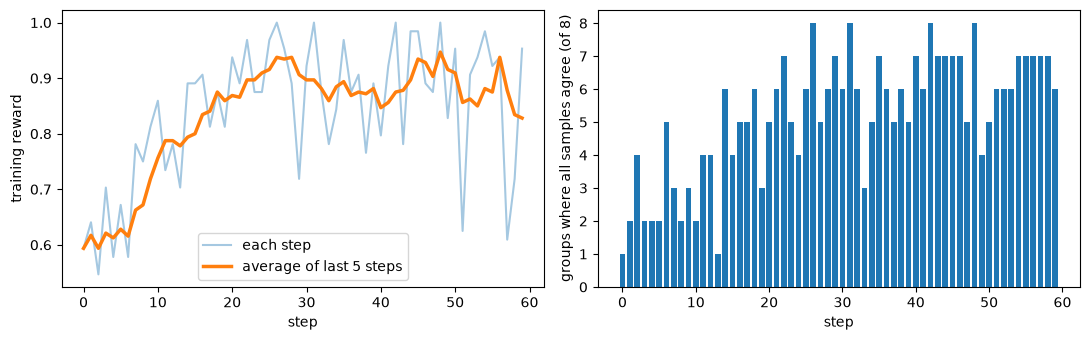

greedy accuracy on held-out problems: 0.765 before → 0.860 after 60 steps


In [60]:
history_table = pd.DataFrame(history)

fig, (reward_axis, same_axis) = plt.subplots(1, 2, figsize=(11, 3.5))

reward_axis.plot(history_table["reward"], alpha=0.4, label="each step")
reward_axis.plot(history_table["reward"].rolling(5, min_periods=1).mean(), linewidth=2.5, label="average of last 5 steps")
reward_axis.set_xlabel("step")
reward_axis.set_ylabel("training reward")
reward_axis.legend()

same_axis.bar(history_table.index, history_table["groups_all_same"])
same_axis.set_xlabel("step")
same_axis.set_ylabel(f"groups where all samples agree (of {QUESTIONS_PER_STEP})")

plt.tight_layout()
plt.show()

accuracy_after = evaluate(hf_generate_greedy)
print(f"greedy accuracy on held-out problems: {accuracy_before:.3f} before → {accuracy_after:.3f} after {NUM_STEPS} steps")

As we can see, **the training reward goes up** over the first 15 steps or so, from around 0.6 to around 0.9, and then stays around there, noisily; this is expected, as every step uses different questions, and some are much harder than others. The responses also get slightly shorter, from about 150 tokens to about 135. In our run, held-out accuracy went from 0.765 to 0.860. However, the exact number should be treated with some care: 200 questions is a noisy measure, as one question is worth half a percentage point, and, as we'll see in §1.9, two runs of the same code can end quite far apart.

The right-hand plot shows a cost of this progress. As the model gets better, more groups are *always right*; these groups have zero advantage and teach the model nothing, but they still cost a full share of generation. Towards the end of training, more than half of each step's samples are wasted in this way. Real training runs deal with this by filtering out questions that are too easy, or by moving on to harder ones (try `make_problems(..., hard=True)`).

### 1.9 More than one update per batch: the last ingredient of GRPO

If we look at the timings from our training run, generation takes several times longer than the update, and for bigger models and longer responses, it can dominate completely. Yet, after all that work, we only use each batch of samples for **one** optimizer step, before throwing it away.

In practice, training loops often get more out of each batch by splitting it into **mini-batches**, and taking one optimizer step per mini-batch. For example, if we split our 64 samples into 2 mini-batches of 32, each batch gives us 2 optimizer steps. Each sample is still only trained on once; what gets reused is the expensive round of generation.

However, this introduces a problem. After the first mini-batch's step, the weights have changed, but the second mini-batch's samples were generated by the *old* weights, and our loss has no idea how far the policy has already moved. If we repeat this over several mini-batches, or several passes over the same batch, there is nothing to stop one batch from pushing some tokens much further than one batch of evidence justifies.

PPO's solution, which GRPO also uses, is to keep track of how far each token has moved since it was sampled, using the **ratio**:

$$\rho = \frac{\pi_\theta(\text{token})}{\pi_\text{old}(\text{token})}$$

where π_old is the token's probability when it was sampled (before any update), and π_θ is its probability now. ρ = 1 means that the token is unchanged, and ρ = 1.2 means that it is 20% more likely than when it was sampled.

PPO then **clips** the objective: once a token has moved far enough in the direction its advantage wants (ρ above 1.28 for a token with a positive advantage, or below 0.8 for one with a negative advantage), its gradient becomes zero, so the batch can't push it any further. If a token has moved the *wrong* way, the gradient still flows, so the update can undo it.

Let's see what this means for a single token that had a probability of 0.10 when it was sampled:

In [61]:
old_prob = 0.10           # π_old: the token's probability when it was sampled
clip_low, clip_high = 0.2, 0.28

for advantage in [+1.0, -1.0]:
    print(f"advantage A = {advantage:+.0f}")
    print(f"  {'new prob':>8}  {'ratio ρ':>7}  {'ρ·A':>6}  {'clip(ρ)·A':>9}  gradient")
    for new_prob in [0.05, 0.09, 0.10, 0.12, 0.15, 0.30]:
        ratio = new_prob / old_prob
        unclipped_objective = ratio * advantage
        clipped_objective = min(max(ratio, 1 - clip_low), 1 + clip_high) * advantage
        if clipped_objective < unclipped_objective:
            gradient = "zero: moved far enough, stop pushing"
        else:
            gradient = "flows"
        print(f"  {new_prob:8.2f}  {ratio:7.2f}  {unclipped_objective:+6.2f}  {clipped_objective:+9.2f}  {gradient}")
    print()

advantage A = +1
  new prob  ratio ρ     ρ·A  clip(ρ)·A  gradient
      0.05     0.50   +0.50      +0.80  flows
      0.09     0.90   +0.90      +0.90  flows
      0.10     1.00   +1.00      +1.00  flows
      0.12     1.20   +1.20      +1.20  flows
      0.15     1.50   +1.50      +1.28  zero: moved far enough, stop pushing
      0.30     3.00   +3.00      +1.28  zero: moved far enough, stop pushing

advantage A = -1
  new prob  ratio ρ     ρ·A  clip(ρ)·A  gradient
      0.05     0.50   -0.50      -0.80  zero: moved far enough, stop pushing
      0.09     0.90   -0.90      -0.90  flows
      0.10     1.00   -1.00      -1.00  flows
      0.12     1.20   -1.20      -1.20  flows
      0.15     1.50   -1.50      -1.28  flows
      0.30     3.00   -3.00      -1.28  flows



PPO takes the **smaller**, or more pessimistic, of the two objectives, ρ·A and clip(ρ)·A. Looking at the A = +1 table, while the token's probability rises from 0.10 towards 0.128 (ρ = 1.28), the plain ρ·A is the smaller of the two, so the gradient keeps pushing it up. Beyond that (0.15 and 0.30), the clipped value is smaller, and as it is a constant, the gradient is zero. If the token had moved the *wrong* way (0.05 and 0.09), ρ·A is still the smaller one, so the gradient flows and can pull it back. The A = −1 table is the mirror image of this, with the limit at ρ = 0.8.

You may have noticed that the limits are asymmetric: 0.8 and 1.28, rather than 0.8 and 1.2. This is the "clip-higher" trick from DAPO ([Yu et al., 2025](https://arxiv.org/abs/2503.14476)), which leaves a bit more room to raise unlikely tokens with a positive advantage.

Written as a loss (the negative of the objective), for each token, this becomes:

In [ ]:
def clipped_token_losses(token_log_probs: torch.Tensor, old_token_log_probs: torch.Tensor, advantage: float,
                         clip_low: float = 0.2, clip_high: float = 0.28) -> torch.Tensor:
    """PPO's clipped loss for each token of one response."""
    
    ratio = torch.exp(token_log_probs - old_token_log_probs)  # π_θ / π_old, computed from log-probs
    
    unclipped_loss = -advantage * ratio
    clipped_loss = -advantage * ratio.clamp(1 - clip_low, 1 + clip_high)
    
    return torch.maximum(unclipped_loss, clipped_loss)  # the larger loss = the smaller (more pessimistic) objective

Note that, **on the first mini-batch, this is exactly the same as our old loss**. As nothing has been updated yet, π_θ = π_old, so ρ = 1 for every token, which is well inside the clip range. The loss is −A × ρ, and as π_old is a fixed number recorded before the update, increasing ρ means increasing π_θ. It is even the same size of push as our old loss, −A × log π_θ: near ρ = 1, a small change in log π_θ changes ρ by the same small amount (as ρ = e^(log π_θ − log π_old), and e^x ≈ 1 + x when x is small). This means that the first optimizer step is the same as before; the clipping only has an effect from the second mini-batch onwards.

To use this loss, our training step needs one extra stage, between computing the advantages and updating the weights: recording every token's log-prob **before** any update (π_old). To do this, we define `compute_log_probs`, which runs `batch_log_probs` over the whole batch, 16 rows at a time, without gradients, as π_old is a fixed number that we only read.

In [ ]:
def compute_log_probs(model, batch, micro_batch_size: int = 16) -> torch.Tensor:
    
    with torch.no_grad():
        model.eval()
        
        num_rows = batch["input_ids"].shape[0]
        chunks = []
        
        for start in range(0, num_rows, micro_batch_size):
            micro_batch = select_rows(batch, slice(start, start + micro_batch_size))
            chunks.append(batch_log_probs(model, micro_batch))
    
    model.train()  # back to training mode, so ppo_update gets gradient checkpointing again
    return torch.cat(chunks).cpu()

Next, we define `ppo_clip_loss`, which applies `clipped_token_losses` to a whole micro-batch. Here, `advantages` has one value per token, with shape (rows, response_width), as each sample's advantage is copied onto every one of its tokens. As in §1.8, the loss is masked and divided by `num_trained_tokens`.

In [64]:
def ppo_clip_loss(log_probs, old_log_probs, advantages, mask, num_trained_tokens, clip_low: float = 0.2, clip_high: float = 0.28):
    ratio = torch.exp(log_probs - old_log_probs)  # ρ = π_θ / π_old, per token
    
    unclipped = -advantages * ratio
    
    clipped = -advantages * ratio.clamp(1 - clip_low, 1 + clip_high)
    
    loss = torch.maximum(unclipped, clipped)  # the larger loss = the smaller (more pessimistic) objective
    
    return (loss * mask).sum() / num_trained_tokens     # mean over trained tokens; num_trained_tokens counts the whole mini-batch (see ppo_update)

Now, we can define `ppo_update`, which wraps §1.8's micro-batch loop in a loop over **mini-batches**, taking one optimizer step for each. As each optimizer step now averages over a mini-batch, `num_trained_tokens` counts the trained tokens of the mini-batch, rather than the whole batch. The loss function is passed in as an argument, `loss_fn`, so that, in §2, we can swap in verl's version.

To help us see what the clipping is doing, `ppo_update` also reports the ratio ρ of every trained token, as each micro-batch saw it: the smallest, the largest, and `clip_fraction`, the share of tokens outside the clip range [0.8, 1.28]. (verl reports a similar number, `pg_clipfrac`, but only counts the tokens where the clip actually removes the gradient.)

In [ ]:
def ppo_update(model, optimizer, batch, old_log_probs, advantages, mini_batch_size: int = 64, micro_batch_size: int = 8, loss_fn=ppo_clip_loss) -> dict:
    """One pass over the batch: one optimizer step per mini-batch, gradient accumulation over micro-batches."""
    
    num_rows = batch["input_ids"].shape[0]
    grad_norms = []
    trained_token_ratios = []  # ρ = π_θ / π_old of every trained token, for monitoring
    
    for mini_start in range(0, num_rows, mini_batch_size):
        mini_end = min(mini_start + mini_batch_size, num_rows)
        num_trained_tokens = batch["response_mask"][mini_start:mini_end].sum().item()  # trained tokens in the whole mini-batch

        # Accumulate gradients over micro-batches small enough to fit in memory
        for micro_start in range(mini_start, mini_end, micro_batch_size):
            row_slice = slice(micro_start, min(micro_start + micro_batch_size, mini_end))
            micro_batch = select_rows(batch, row_slice)
            
            log_probs = batch_log_probs(model, micro_batch, with_grad=True)
            mask = micro_batch["response_mask"].to(DEVICE).float()
            micro_old_log_probs = old_log_probs[row_slice].to(DEVICE)
            
            loss = loss_fn(log_probs, micro_old_log_probs, advantages[row_slice].to(DEVICE), mask, num_trained_tokens)
            loss.backward()

            ratio = torch.exp(log_probs.detach() - micro_old_log_probs)
            trained_token_ratios.append(ratio[mask.bool()].cpu())

        # Then one optimizer step for the mini-batch
        grad_norms.append(torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0).item())
        optimizer.step()
        optimizer.zero_grad(set_to_none=True)

    ratios = torch.cat(trained_token_ratios)
    outside_clip_range = (ratios < 0.8) | (ratios > 1.28)  # ppo_clip_loss's default clip range
    return {
        "grad_norm": float(np.mean(grad_norms)),
        "ratio_min": ratios.min().item(),
        "ratio_max": ratios.max().item(),
        "clip_fraction": outside_clip_range.float().mean().item(),
    }

Finally, we can put this together into `rl_step_with_reuse`, which is the same as `rl_step_basic`, except that it records π_old before the update, and uses `ppo_update` in place of the single update.

In [66]:
def rl_step_with_reuse(policy, optimizer, problems: list[dict], samples_per_prompt: int = 8, num_mini_batches: int = 2) -> dict:
    """Like rl_step_basic, but splits the batch into mini-batches: one optimizer step each, with PPO's clipped loss."""

    # 1. Sample (stages 1-3 exactly as in rl_step_basic)
    prompts = [chat_prompt_ids(problem["question"]) for problem in problems]
    samples = hf_generate(policy, prompts, samples_per_prompt)
    group_ids = [sample_idx // samples_per_prompt for sample_idx in range(len(samples))]

    # 2. Reward: check each response against its own problem's answer
    rewards = []
    for sample, group_id in zip(samples, group_ids):
        rewards.append(reward_fn(decode_tokens(sample["response_ids"]), problems[group_id]["answer"]))
    rewards = torch.tensor(rewards, dtype=torch.float32)

    # 3. Advantages, within each problem's group
    advantages = grpo_advantages(rewards, group_ids)

    # Pad everything into one batch, for π_old and the update
    batch = make_padded_batch([sample["prompt_ids"] for sample in samples], [sample["response_ids"] for sample in samples])

    # New: every token's log-prob under the weights that generated the samples (π_old), before any update
    old_log_probs = compute_log_probs(policy, batch)

    # 4. Update: one optimizer step per mini-batch, with PPO's clipped loss
    token_advantages = advantages.unsqueeze(-1) * batch["response_mask"]  # (rows, response_width): each sample's advantage on all its tokens
    mini_batch_size = len(samples) // num_mini_batches
    update_stats = ppo_update(policy, optimizer, batch, old_log_probs, token_advantages, mini_batch_size=mini_batch_size)

    return {"reward": rewards.mean().item(), **update_stats}

Let's run the same experiment as before, starting from the original model and using the same batches of questions (with the same `question_rng` seed), but this time taking 2 optimizer steps per batch instead of 1. The generation cost stays the same; only the number of updates doubles.

Each line of the output also shows the ratios. In the first mini-batch, nothing has been updated yet, so ρ ≈ 1; the spread comes from the second mini-batch, where the policy has already moved since the samples were generated.

In [67]:
policy.load_state_dict(original_weights)
optimizer = torch.optim.AdamW(policy.parameters(), lr=LR, weight_decay=0.01)
question_rng = random.Random(0)  # the same questions as the first run
history_with_reuse = []

for step in range(NUM_STEPS):
    problems = question_rng.sample(TRAIN, QUESTIONS_PER_STEP)
    metrics = rl_step_with_reuse(policy, optimizer, problems, samples_per_prompt=SAMPLES_PER_QUESTION, num_mini_batches=2)
    history_with_reuse.append(metrics)

    print(f"step {step:2d} | reward {metrics['reward']:.3f} | ratio {metrics['ratio_min']:.2f} to {metrics['ratio_max']:.2f}, "
          f"{metrics['clip_fraction']:.2%} of tokens outside [0.8, 1.28]")

step  0 | reward 0.562 | ratio 0.78 to 1.28, 0.04% of tokens outside [0.8, 1.28]


step  1 | reward 0.531 | ratio 0.70 to 1.28, 0.06% of tokens outside [0.8, 1.28]


step  2 | reward 0.516 | ratio 0.49 to 1.26, 0.36% of tokens outside [0.8, 1.28]


step  3 | reward 0.891 | ratio 0.70 to 1.28, 0.03% of tokens outside [0.8, 1.28]


step  4 | reward 0.625 | ratio 0.42 to 1.50, 0.20% of tokens outside [0.8, 1.28]


step  5 | reward 0.672 | ratio 0.39 to 1.52, 0.15% of tokens outside [0.8, 1.28]


... (50 outputs left out)

step 56 | reward 0.859 | ratio 0.58 to 1.57, 0.27% of tokens outside [0.8, 1.28]


step 57 | reward 0.609 | ratio 0.24 to 1.54, 0.19% of tokens outside [0.8, 1.28]


step 58 | reward 0.844 | ratio 0.45 to 1.63, 0.19% of tokens outside [0.8, 1.28]


step 59 | reward 0.875 | ratio 0.60 to 1.48, 0.19% of tokens outside [0.8, 1.28]


The ratios show why we need π_old. They typically range from about 0.5 to 1.5, with the odd token much further out, so by the second mini-batch, the samples really are "out of date". However, only a small fraction of tokens, usually well under 1% of the batch, move outside [0.8, 1.28], so the clipping rarely kicks in. This is normal: with a small learning rate and only 2 mini-batches, it acts as a **safety net**. It matters when a step moves the policy further, for example with more mini-batches, several passes (*epochs*) over the same batch, a larger learning rate, or an unusual batch. Without it, every one of those extra steps would keep pushing the same tokens with the same force.

So, does taking more than one update per batch actually help? Unfortunately, a single run of each can't tell us. This is because GPU arithmetic isn't bit-exact: a backward pass adds numbers up in an order that varies from run to run, so the weights after the first update differ in their last few bits. Sooner or later, at some near-tie, a different token gets sampled, and from then on, the run takes a different path. As a result, two runs of the same code with the same seed can end several percentage points apart, which is larger than the difference we're trying to measure.

To answer this question properly, we ran the comparison outside the notebook: 3 seeds per setting, 60 steps of 16 questions × 8 samples, with greedy accuracy measured on 1,000 held-out questions every 10 steps. As this uses `rl_step` from §2 and the vLLM inference engine from notebook 2, all 12 runs take about an hour, rather than several hours. The script is `tools/reuse_experiment.py`, and its results are saved in the repo:

1 update per batch           accuracy at step 60: mean 0.929, seeds 0.921, 0.931, 0.934
2 updates per batch          accuracy at step 60: mean 0.870, seeds 0.876, 0.896, 0.839
4 updates per batch          accuracy at step 60: mean 0.841, seeds 0.865, 0.838, 0.819
4 updates, ¼ learning rate   accuracy at step 60: mean 0.942, seeds 0.946, 0.946, 0.934


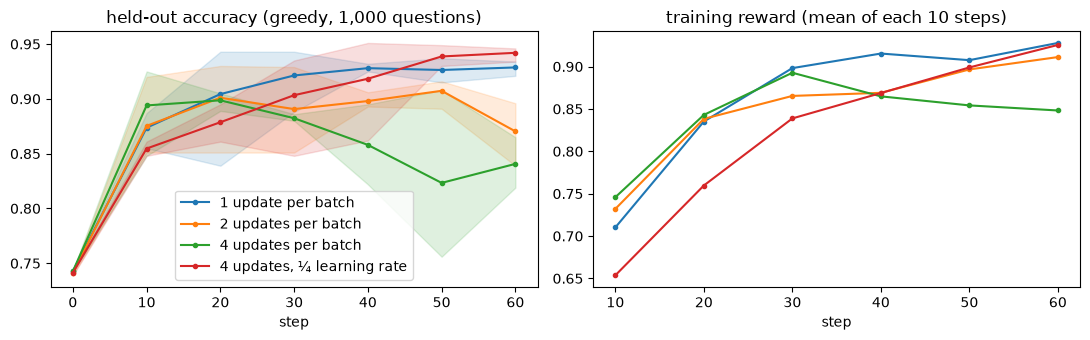

In [ ]:
import json

reuse_runs = [json.loads(line) for line in open(REPO / "tutorial/series/results/reuse_experiment.jsonl")]
settings = {"1": "1 update per batch", "2": "2 updates per batch", "4": "4 updates per batch", "4_lr/4": "4 updates, ¼ learning rate"}

fig, (accuracy_axis, reward_axis) = plt.subplots(1, 2, figsize=(11, 3.5))
for setting, label in settings.items():
    runs = [run for run in reuse_runs if run["setting"] == setting]
    eval_steps = [int(step) for step in runs[0]["accuracy"]]
    accuracy = np.array([[run["accuracy"][str(step)] for step in eval_steps] for run in runs])  # (seeds, checkpoints)
    line, = accuracy_axis.plot(eval_steps, accuracy.mean(0), marker="o", ms=3, label=label)
    accuracy_axis.fill_between(eval_steps, accuracy.min(0), accuracy.max(0), color=line.get_color(), alpha=0.15)  # lowest to highest seed

    rewards = np.array([run["rewards"] for run in runs]).mean(0)  # mean over seeds, one value per step
    reward_axis.plot(range(10, len(rewards) + 1, 10), rewards.reshape(-1, 10).mean(1), marker="o", ms=3, label=label)  # mean of each 10 steps

    print(f"{label:28s} accuracy at step {eval_steps[-1]}: mean {accuracy[:, -1].mean():.3f}, "
          f"seeds {', '.join(f'{value:.3f}' for value in accuracy[:, -1])}")

accuracy_axis.set(title="held-out accuracy (greedy, 1,000 questions)", xlabel="step")
reward_axis.set(title="training reward (mean of each 10 steps)", xlabel="step")
accuracy_axis.legend()
plt.tight_layout()
plt.show()

Each line is the mean of 3 seeds, and the shaded band runs from the lowest seed to the highest.

With **1 update per batch**, training is steady: every seed ends between 0.92 and 0.94. With **more updates per batch at the same learning rate**, accuracy starts out level or slightly ahead, but then falls back; with 4 updates, accuracy actually gets *worse* as training goes on, and the training reward drops with it, so it isn't just an evaluation fluke. However, with **4 updates at a quarter of the learning rate**, the model learns more slowly at first, but doesn't fall back, and ends slightly above 1 update per batch.

This tells us that the problem is the size of each step, rather than the extra updates themselves. Adam moves each weight by roughly the learning rate per step, whatever the size of the gradient, so 4 steps per batch at the same learning rate move the policy about 4 times as far per batch. The clip limits how far a token can move *within* one batch, but it can't stop this drift from adding up over many batches.

So, taking several updates per batch is a trade-off: we get more learning from each round of generation, at the cost of training on samples generated by a slightly older policy. It pays off when generation is expensive (big models, long agent rollouts) and batches are large, as long as the number of mini-batches is tuned together with the learning rate. Here, generation is cheap and the batches are small, so it barely matters.

**This is GRPO in full:** group-relative advantages, plus PPO's clipped ratio for taking several updates per batch. All that's left is to swap in verl's tested versions of our functions (§2), and, in notebook 2, to use a real inference engine for generation.

## 2. Swapping in verl's algorithm functions

Now that we have a working trainer, let's see how it compares with a real RL framework. Throughout the rest of this series, we use [verl](https://github.com/volcengine/verl), which is widely used for training LLMs with RL. Its module `verl.trainer.ppo.core_algos` contains a range of advantage estimators (GAE, GRPO, RLOO, REINFORCE++, …) and policy losses (vanilla PPO-clip, GSPO, CISPO, …), each of which can be selected by name. These are based on the same ideas as ours, but with many more variants, and a lot more care taken over edge cases.

Following the approach from the introduction, we'll replace our hand-written functions with verl's, one at a time; after each swap, we'll check on our real batch that the results are unchanged. We'll swap two of our functions:

| Ours | verl's | What changes |
|---|---|---|
| `grpo_advantages` | `compute_grpo_outcome_advantage` | the rewards are passed in per token, rather than per response |
| `ppo_clip_loss` | `get_policy_loss_fn("vanilla")` | the settings are passed in through a config, and it adds *dual-clip* |

Finally, we'll put them together into a new training step, `rl_step`.

In [ ]:
from omegaconf import OmegaConf  # noqa: E402
from verl.trainer.ppo.core_algos import compute_grpo_outcome_advantage, get_policy_loss_fn  # noqa: E402

#### Advantages

The main difference in verl's advantage function is that **it expects one reward per token, rather than one per response**. It takes `token_level_rewards`, a tensor with the same shape as the responses, (rows, response_width). This is a more general format than ours, as some setups give rewards along the way, such as a small penalty on every token, or a reward for each step of a multi-step agent. As our reward is a single number for the whole response, we put it on the response's **last real token**, and set every other token to 0:

![A response with reward 1: token_level_rewards is 1 on its last real token and 0 everywhere else, including the padding](images/token_level_rewards.png)

As GRPO only needs one number per response, verl's GRPO function adds up each row, which gives back our original reward. Let's look at the first two samples of our batch:

In [ ]:
response_mask = example_batch["response_mask"]
response_lengths = response_mask.sum(-1)  # real response tokens per row

# Each response's reward, on its last real token
token_level_rewards = torch.zeros(response_mask.shape)
token_level_rewards[torch.arange(len(response_lengths)), response_lengths - 1] = example_rewards

for row in range(2):
    nonzero_columns = token_level_rewards[row].nonzero().flatten().tolist()
    print(f"row {row}: {response_lengths[row].item()} response tokens, reward {example_rewards[row].item():.0f} → "
          f"token_level_rewards is nonzero at columns {nonzero_columns}, row sum {token_level_rewards[row].sum().item():.0f}")

row 0: 163 response tokens, reward 1 → token_level_rewards is nonzero at columns [162], row sum 1
row 1: 146 response tokens, reward 1 → token_level_rewards is nonzero at columns [145], row sum 1


Note that a row with a reward of 0 has no nonzero column at all, as a reward of 0 on the last token is still 0.

Now, let's compute the advantages with both functions. As verl returns one advantage per *token*, with each sample's advantage copied onto all of its response tokens, we spread ours out in the same way so that we can compare them. Note that verl calls the group IDs `index`, and expects them as a numpy array:

In [ ]:
verl_advantages, _ = compute_grpo_outcome_advantage(
    token_level_rewards=token_level_rewards,
    response_mask=response_mask,
    index=np.array(example_group_ids, dtype=object),  # verl's name for the group IDs
)

our_advantages = grpo_advantages(example_rewards, example_group_ids)  # one per sample
our_token_advantages = our_advantages.unsqueeze(-1) * response_mask   # copied onto every response token

print("question 0's group, ours:  ", [round(advantage, 2) for advantage in our_advantages[:8].tolist()])
print("question 0's group, verl's:", [round(advantage, 2) for advantage in verl_advantages[:8, 0].tolist()], "(first token of each response)")
print("\nall advantages match:", torch.allclose(our_token_advantages, verl_advantages, atol=1e-5))

question 0's group, ours:   [0.72, 0.72, 0.72, -1.21, -1.21, 0.72, -1.21, 0.72]
question 0's group, verl's: [0.72, 0.72, 0.72, -1.21, -1.21, 0.72, -1.21, 0.72] (first token of each response)

all advantages match: True


As we can see, verl's advantages are exactly the same as ours.

#### The loss

verl's vanilla policy loss computes the same thing as our `ppo_clip_loss`, but takes its settings in a different way: rather than as arguments, they come from a config object. This contains the clip range (`clip_ratio_low` and `clip_ratio_high`), and the number of tokens to average over, in `global_batch_info`. This count is our `num_trained_tokens`, as verl handles micro-batches in the same way as `ppo_update`. The config also has one extra setting, `clip_ratio_c`, which is used for *dual-clip*; we'll come back to this shortly.

So that `ppo_update` can use either loss, we wrap verl's in `verl_ppo_loss`, which takes the same arguments as `ppo_clip_loss`:

In [ ]:
verl_policy_loss = get_policy_loss_fn("vanilla")


def verl_ppo_loss(log_probs, old_log_probs, advantages, mask, num_trained_tokens, clip_low=0.2, clip_high=0.28, clip_c=3.0):
    config = OmegaConf.create({
        "clip_ratio": clip_low, "clip_ratio_low": clip_low, "clip_ratio_high": clip_high, "clip_ratio_c": clip_c,
        "global_batch_info": {"batch_num_tokens": num_trained_tokens, "dp_size": 1},
    })
    loss, _ = verl_policy_loss(old_log_prob=old_log_probs, log_prob=log_probs, advantages=advantages, response_mask=mask, loss_agg_mode="token-mean", config=config)
    return loss

To check that the two losses match, we need ratios far enough from 1 for the clipping to have an effect. To get these, we make up π_old and π_θ log-probs for our batch, with the new ones moved randomly away from the old ones. Then, we compare three losses: ours, verl's with dual-clip switched off, and verl's default, with dual-clip switched on:

In [ ]:
made_up_old_log_probs = -torch.rand(response_mask.shape)
made_up_new_log_probs = made_up_old_log_probs + 0.5 * torch.randn(response_mask.shape)  # far enough from the old ones that clipping kicks in

loss_inputs = {
    "log_probs": made_up_new_log_probs,
    "old_log_probs": made_up_old_log_probs,
    "advantages": verl_advantages,
    "mask": response_mask.float(),
    "num_trained_tokens": response_mask.sum().item(),
}
print(f"ours (ppo_clip_loss):         {ppo_clip_loss(**loss_inputs):.6f}")
print(f"verl's, dual-clip off:        {verl_ppo_loss(**loss_inputs, clip_c=1e9):.6f}")
print(f"verl's, dual-clip on (c = 3): {verl_ppo_loss(**loss_inputs):.6f}")

ours (ppo_clip_loss):         0.093282
verl's, dual-clip off:        0.093282
verl's, dual-clip on (c = 3): 0.089695


As we can see, with dual-clip switched off, verl's loss matches ours to the last digit, whereas with it switched on (verl's default, `clip_ratio_c=3`), the two differ slightly.

**Dual-clip** fixes a gap in plain PPO-clip, which we saw in the A = −1 table in §1.9: when a token with a *negative* advantage has become much *more* likely (a large ratio), the loss −A × ρ keeps growing with the ratio, with no limit. This means that a single token whose probability has shot up could dominate the whole update. Dual-clip avoids this by capping the loss at c × |A|. Let's see what this looks like for a token with A = −1:

In [ ]:
advantage = -1.0
clip_low, clip_high, clip_c = 0.2, 0.28, 3.0

print(f"{'ratio ρ':>8} {'PPO-clip loss':>14} {'with dual-clip':>15}")
for ratio in [0.5, 1.0, 2.0, 3.0, 5.0, 10.0]:
    clipped_ratio = min(max(ratio, 1 - clip_low), 1 + clip_high)
    ppo_loss = max(-advantage * ratio, -advantage * clipped_ratio)  # ppo_clip_loss, for one token
    dual_clip_loss = min(ppo_loss, -advantage * clip_c)             # verl: never more than c·|A| (negative A only)
    print(f"{ratio:8.1f} {ppo_loss:14.2f} {dual_clip_loss:15.2f}")

 ratio ρ  PPO-clip loss  with dual-clip
     0.5           0.80            0.80
     1.0           1.00            1.00
     2.0           2.00            2.00
     3.0           3.00            3.00
     5.0           5.00            3.00
    10.0          10.00            3.00


As we can see, the two are the same up to ρ = 3; beyond that, dual-clip holds the loss at 3. Our made-up ratios include a few tokens like this, which account for the whole difference between the two losses above. In real training, the ratios stay close to 1, so tokens like this are rare.

#### The training step, with verl's functions

Finally, let's put this together into `rl_step`. This follows the same four stages as `rl_step_basic` from §1.8, **sample → reward → advantage → update**, but records π_old and uses `ppo_update`, as in §1.9, and uses verl's functions in place of ours. The sample and reward stages are unchanged; the rest differs as follows:

| Stage | `rl_step_basic` (§1.8) | `rl_step` |
|---|---|---|
| π_old | none: one optimizer step per batch | `compute_log_probs` before the update (§1.9) |
| 3. Advantage | `grpo_advantages`: one number per sample | rewards on each response's last token, then verl's `compute_grpo_outcome_advantage`: shape (64, response_width), each sample's advantage on all its tokens |
| 4. Update | −A × log π, one optimizer step | `ppo_update` with `loss_fn=verl_ppo_loss`: PPO-clip, one optimizer step per mini-batch |

There are also two other changes:

* `rl_step` takes the **generation function** as an argument, `generate`, in the same way as `evaluate`. This means that, in notebook 2, we can swap in a faster inference engine without changing anything else.
* The metrics include `format`: the fraction of responses that contain a `\boxed{}` number at all, whether right or wrong. This lets us tell whether the model has learned the format, or the arithmetic.

In [ ]:
def rl_step(policy, optimizer, generate, problems, samples_per_prompt: int = 8, **update_kwargs) -> tuple[dict, dict, list[dict]]:
    timing = {}

    # 1. Sample several responses per problem (a GRPO group). Samples are prompt-major: sample i answers problem i // samples_per_prompt
    start = time.time()
    samples = generate([chat_prompt_ids(problem["question"]) for problem in problems], samples_per_prompt)
    timing["gen"] = time.time() - start
    group_ids = [i // samples_per_prompt for i in range(len(samples))]

    # 2. Score each response, then pad everything into one batch (for π_old, the advantages and the update)
    texts = [decode_tokens(sample["response_ids"]) for sample in samples]
    rewards = torch.tensor([reward_fn(text, problems[group]["answer"]) for text, group in zip(texts, group_ids)])
    batch = make_padded_batch([sample["prompt_ids"] for sample in samples], [sample["response_ids"] for sample in samples])

    # π_old: log-probs under the weights that generated the samples (§1.9)
    start = time.time()
    old_log_probs = compute_log_probs(policy, batch)
    timing["old_log_prob"] = time.time() - start

    # 3. Advantages with verl's GRPO estimator, which takes each response's reward on its last token
    last_token = batch["response_mask"].sum(-1).clamp(min=1) - 1
    token_level_rewards = torch.zeros(batch["response_mask"].shape)
    token_level_rewards[torch.arange(len(samples)), last_token] = rewards
    advantages, _ = compute_grpo_outcome_advantage(
        token_level_rewards=token_level_rewards, response_mask=batch["response_mask"], index=np.array(group_ids, dtype=object),
    )
    batch.update(old_log_probs=old_log_probs, advantages=advantages)  # kept for inspection after the update

    # 4. Update: PPO, with verl's loss
    start = time.time()
    stats = ppo_update(policy, optimizer, batch, old_log_probs, advantages, loss_fn=verl_ppo_loss, **update_kwargs)
    timing["update"] = time.time() - start

    metrics = {
        "reward": rewards.mean().item(),
        "format": float(np.mean([bool(BOXED.search(text)) for text in texts])),  # has a \boxed{integer} at all, right or wrong
        "response_len": batch["response_mask"].sum(-1).float().mean().item(),
        **stats,
    }
    metrics.update({f"time/{name}": seconds for name, seconds in timing.items()})
    return metrics, batch, samples


def print_step_metrics(step: int, metrics: dict) -> None:
    fmt = f" | format {metrics['format']:.2f}" if "format" in metrics else ""
    mismatch = f" | logp mismatch {metrics['logp_mismatch']:.4f}" if "logp_mismatch" in metrics else ""
    times = " ".join(f"{name.removeprefix('time/')} {seconds:4.1f}s" for name, seconds in metrics.items() if name.startswith("time/"))
    print(f"step {step:2d} | reward {metrics['reward']:.3f}{fmt} | len {metrics['response_len']:5.1f} | grad_norm {metrics['grad_norm']:.3f}{mismatch} | {times}")

Let's run a few steps with `hf_generate`, continuing from the model we trained in §1.9, to check that everything fits together:

In [ ]:
for step in range(3):
    problems = question_rng.sample(TRAIN, QUESTIONS_PER_STEP)
    metrics, batch, samples = rl_step(policy, optimizer, lambda prompts, samples_per_prompt: hf_generate(policy, prompts, samples_per_prompt), problems)
    print_step_metrics(step, metrics)

step  0 | reward 1.000 | format 1.00 | len 123.6 | grad_norm 0.000 | gen  6.2s old_log_prob  0.1s update  1.1s


step  1 | reward 0.828 | format 1.00 | len 128.7 | grad_norm 2.038 | gen  6.4s old_log_prob  0.1s update  1.1s


step  2 | reward 1.000 | format 1.00 | len 131.5 | grad_norm 0.000 | gen  6.4s old_log_prob  0.1s update  1.1s


As we can see, the timings are the same as for our own trainer: the update takes about 1 s, and computing π_old about 0.1 s, whereas generating 64 samples with `hf_generate` takes about 6 s. Note that, in a step where every sample is correct, every advantage is 0, so the gradient norm is 0 too.

This means that generation now takes up almost all of each step. This is the next thing to fix, and where notebook 2 starts.

## What we built

Over this notebook, we've built a complete GRPO trainer, one piece at a time:

| Problem | Solution | In code |
|---|---|---|
| How likely is a response? | sum the log-probs of its tokens, from one forward pass | `response_token_log_probs` → `batch_log_probs` |
| Make good responses more likely | minimise −reward × log π (REINFORCE) | `loss.backward()`, `optimizer.step()` |
| Wrong answers are ignored; easy questions still get pushed | compare with the group: advantage = (reward − mean) / std | `grpo_advantages` |
| Putting it together | one training step: sample → reward → advantage → update | `rl_step_one_question` |
| A real step uses many questions | one group per question, advantages within each group | `rl_step_basic` |
| One sample at a time is too slow | pad a step's samples into one batch; micro-batches to fit in memory, every one divided by the whole batch's token count | `hf_generate`, `make_padded_batch`, `batch_log_probs` |
| We throw samples away after one step | several mini-batch steps per batch, with PPO's clipped ratio | `ppo_clip_loss`, `ppo_update` |
| Our maths, in battle-tested code | verl's advantage and loss functions, checked against ours | `compute_grpo_outcome_advantage`, `verl_ppo_loss`, `rl_step` |

Every function that the rest of the series needs is also in `tutorial/lib/rl_core.py`, so later notebooks can import them, rather than re-running this one.

**Next:** in [notebook 2](2_from_trainer_to_verl.ipynb), we'll fix the slowest part of each step, generation, by handing it to a real inference engine (vLLM). Then, we'll swap our batch for verl's `DataProto`, and split this trainer into separate processes, as verl does at scale, one swap at a time, until it *is* verl. Before that, let's free up the GPU:

In [ ]:
import gc

del policy, optimizer
gc.collect()
torch.cuda.empty_cache()
print(f"GPU free: {gpu_free_gib():.0f} GiB")

GPU free: 79 GiB


## Appendix: what did that step actually do?

In §1.5, we saw each response's log π move up or down as a whole after a training step with advantages. However, a response is made up of tokens, and the update doesn't treat them all equally. **So, which tokens does it make more likely, and which less likely?** As our real responses are too long to follow by hand, let's work through a small example instead: 10 responses to one question, where only one is correct.

First, let's compute its GRPO advantages:

In [ ]:
# 10 responses to one question; only the first one is correct
example_rewards = torch.tensor([1.0] + [0.0] * 9)

mean_reward = example_rewards.mean()               # 1 right out of 10 = 0.1
reward_minus_mean = example_rewards - mean_reward  # +0.9 for the winner, -0.1 for each loser
std_reward = example_rewards.std()                 # sqrt((0.9**2 + 9 * 0.1**2) / 9): torch.std divides by n - 1 = 9, not 10
example_advantages = reward_minus_mean / std_reward

print(f"rewards: {example_rewards.tolist()}")
print(f"mean reward:        {mean_reward:.2f}")
print(f"reward - mean:      winner {reward_minus_mean[0]:+.2f}, each loser {reward_minus_mean[1]:+.2f}")
print(f"standard deviation: {std_reward:.3f}")
print(f"advantage:          winner {example_advantages[0]:+.3f}, each loser {example_advantages[1]:+.3f}")

rewards: [1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
mean reward:        0.10
reward - mean:      winner +0.90, each loser -0.10
standard deviation: 0.316
advantage:          winner +2.846, each loser -0.316


As our loss for the whole group adds up every sample's loss:

$$\text{loss} = -\sum_i A_i \log \pi(\text{response}_i)$$

one gradient-descent step moves the weights θ in the direction

$$\Delta\theta \;\propto\; \underbrace{2.846\,\nabla \log \pi(\text{winner})}_{\text{one strong push up}} \;-\; \underbrace{0.316\,\big[\nabla \log \pi(\text{loser}_1) + \dots + \nabla \log \pi(\text{loser}_9)\big]}_{\text{nine weak pushes down}}$$

We can think of ∇log π(response) as *the direction in which to change the weights so that this response becomes more likely*. As each response is made up of different tokens, each has its own direction. So, this step moves the weights strongly in the winner's direction, and slightly away from each loser's. Although the advantages add up to zero, they multiply different gradients, so only what the responses have in common cancels out. But what exactly do they have in common?

To find out, recall from §1.3 that log π(response) is a sum, with one term per token:

$$\log \pi(\text{response}) = \log p(\text{token}_1 \mid \text{prompt}) + \log p(\text{token}_2 \mid \text{prompt}, \text{token}_1) + \dots$$

As the gradient of a sum is the sum of the gradients, ∇log π(response) splits up in the same way:

$$\nabla \log \pi(\text{response}) = \nabla \log p(\text{token}_1 \mid \text{prompt}) + \nabla \log p(\text{token}_2 \mid \text{prompt}, \text{token}_1) + \dots$$

As the model predicts each token only from the text **before** it, each term depends on only two things: the text before the token, and the token itself. This means that, if two responses contain the **same token after the same text**, they share exactly the same term, with the same gradient, so their weights add up. In contrast, the same token after *different* text is a different term.

To see this in action, let's take a group of 10 responses to "What is 19 × 99 + 10?", and add up the weights term by term. To keep it readable, we've split each response into a few chunks by hand, which stand in for tokens:

In [ ]:
# A hard question, "What is 19 × 99 + 10?", with 1 right answer out of 10.
# Each response is split into a few chunks by hand, standing in for tokens to keep it readable.
winner         = ["To solve this:", " 19 × 99 = 1881,", " plus 10 is 1891."]  # right: 1891
slip_a         = ["To solve this:", " 19 × 99 = 1881,", " plus 10 is 1901."]  # adds wrong
slip_b         = ["To solve this:", " 99 × 19 = 1881,", " plus 10 is 1901."]  # same slip, different wording before it
wrong_multiply = ["To solve this:", " 19 × 99 = 1871,", " plus 10 is 1881."]  # multiplies wrong

hard_group = [winner] + [slip_a] * 4 + [slip_b] * 3 + [wrong_multiply] * 2
hard_group_kinds = ["winner"] + ["slip_a"] * 4 + ["slip_b"] * 3 + ["wrong_multiply"] * 2  # which response is which
hard_group_rewards = [1] + [0] * 9
hard_group_advantages = grpo_group_advantages(hard_group_rewards)

# One row per response, with its chunks side by side so you can see where the responses diverge
hard_group_table = pd.DataFrame(hard_group, columns=["chunk 1", "chunk 2", "chunk 3"])
hard_group_table.insert(0, "kind", hard_group_kinds)
hard_group_table["reward"] = hard_group_rewards
hard_group_table["advantage"] = [round(advantage, 3) for advantage in hard_group_advantages]  # +2.846 for the winner, -0.316 for each loser
hard_group_table

,kind,chunk 1,chunk 2,chunk 3,reward,advantage
0,winner,To solve this:,"19 × 99 = 1881,",plus 10 is 1891.,1,2.846
1,slip_a,To solve this:,"19 × 99 = 1881,",plus 10 is 1901.,0,-0.316
2,slip_a,To solve this:,"19 × 99 = 1881,",plus 10 is 1901.,0,-0.316
3,slip_a,To solve this:,"19 × 99 = 1881,",plus 10 is 1901.,0,-0.316
4,slip_a,To solve this:,"19 × 99 = 1881,",plus 10 is 1901.,0,-0.316
5,slip_b,To solve this:,"99 × 19 = 1881,",plus 10 is 1901.,0,-0.316
6,slip_b,To solve this:,"99 × 19 = 1881,",plus 10 is 1901.,0,-0.316
7,slip_b,To solve this:,"99 × 19 = 1881,",plus 10 is 1901.,0,-0.316
8,wrong_multiply,To solve this:,"19 × 99 = 1871,",plus 10 is 1881.,0,-0.316
9,wrong_multiply,To solve this:,"19 × 99 = 1871,",plus 10 is 1881.,0,-0.316


Reading down the chunk columns, we can see where the responses go their separate ways:

* **Chunk 1** is the same for all 10 responses.
* **Chunk 2** splits three ways: "19 × 99 = 1881," (the winner and the four `slip_a`), "99 × 19 = 1881," (the three `slip_b`) and "19 × 99 = 1871," (the two `wrong_multiply`).
* **Chunk 3**: only the winner wrote "plus 10 is 1891.".

Each response has a single advantage: +2.846 for the winner, and −0.316 for every loser. Next, let's see what these advantages mean for each chunk.

**Step 1: list every term.** First, we break each response into its terms: one per chunk, defined by the chunk and the text before it. As every response starts from the same prompt, we leave the prompt out of the text before.

As the loss multiplies every term in a response by that response's advantage, each term's **weight** is just its response's advantage: +2.846 for every term of the winner, and −0.316 for every term of a loser. Let's look at the first two responses:

In [ ]:
# Step 1: every chunk of every response is one term. It gets its response's advantage as its weight.
term_rows = []
for response_idx, response in enumerate(hard_group):
    advantage = hard_group_advantages[response_idx]
    kind = hard_group_kinds[response_idx]

    for chunk_idx, chunk in enumerate(response):
        text_before = "".join(response[:chunk_idx])  # everything this response wrote before this chunk
        term_rows.append({"response": response_idx, "kind": kind, "text before": text_before, "chunk": chunk, "weight": advantage})

terms = pd.DataFrame(term_rows)
# Round only for display: the sums in step 2 use the full values, so the shared opening still cancels to exactly 0
terms.head(6).round(3)  # the winner's 3 terms, then the first loser's

,response,kind,text before,chunk,weight
0,0,winner,,To solve this:,2.846
1,0,winner,To solve this:,"19 × 99 = 1881,",2.846
2,0,winner,"To solve this: 19 × 99 = 1881,",plus 10 is 1891.,2.846
3,1,slip_a,,To solve this:,-0.316
4,1,slip_a,To solve this:,"19 × 99 = 1881,",-0.316
5,1,slip_a,"To solve this: 19 × 99 = 1881,",plus 10 is 1901.,-0.316


Comparing the winner (rows 0 to 2) with the first loser (rows 3 to 5):

* **Rows 0 and 3** are the same chunk, "To solve this:", after the same (empty) text. So they're the **same term**, appearing once with +2.846 and once with −0.316.
* **Rows 1 and 4** are also the same term: both wrote " 19 × 99 = 1881," after "To solve this:".
* **Rows 2 and 5** are different terms: after the same text, the winner wrote "1891" and the loser "1901".

**Step 2: add up the weights of each term.** Next, across all 10 responses, we group together the rows that are the same term, and add up their weights. This gives us the **key idea: a term's net weight is the sum of the advantages of the responses that contain it.** In the table below, the `responses` column counts these responses, and the `calculation` column writes out the sum.

As each term is log p(chunk | text before it), a **positive** net weight means that the update makes that chunk **more likely** after that text, a **negative** one makes it **less likely**, and **0** leaves it unchanged; the bigger the weight, the bigger the change. The `effect` column spells this out.

In [ ]:
# Step 2: the same chunk after the same text is the same term, so add up its weights
def weights_as_sum(weights: pd.Series) -> str:
    """Write out the sum, e.g. [2.846, -0.316, -0.316] -> '+2.846 + 2 × (-0.316)'. Weights are rounded to 3 decimals for display."""
    weight_counts = weights.round(3).value_counts(sort=False)  # each distinct weight, and how many times it appears
    parts = [f"{weight:+.3f}" if count == 1 else f"{count} × ({weight:+.3f})" for weight, count in weight_counts.items()]
    return " + ".join(parts)


net_weights = (
    terms.groupby(["text before", "chunk"], sort=False)
    .agg(responses=("response", "count"), calculation=("weight", weights_as_sum), net_weight=("weight", "sum"))
    .reset_index()
)
net_weights["net_weight"] = net_weights["net_weight"].round(2) + 0.0  # sums the full values; + 0.0 turns -0.0 into 0.0
net_weights["effect"] = net_weights["net_weight"].map(lambda weight: "more likely" if weight > 0 else "less likely" if weight < 0 else "unchanged")
net_weights

,text before,chunk,responses,calculation,net_weight,effect
0,,To solve this:,10,+2.846 + 9 × (-0.316),0.00,unchanged
1,To solve this:,"19 × 99 = 1881,",5,+2.846 + 4 × (-0.316),1.58,more likely
2,"To solve this: 19 × 99 = 1881,",plus 10 is 1891.,1,+2.846,2.85,more likely
3,"To solve this: 19 × 99 = 1881,",plus 10 is 1901.,4,4 × (-0.316),-1.26,less likely
4,To solve this:,"99 × 19 = 1881,",3,3 × (-0.316),-0.95,less likely
5,"To solve this: 99 × 19 = 1881,",plus 10 is 1901.,3,3 × (-0.316),-0.95,less likely
6,To solve this:,"19 × 99 = 1871,",2,2 × (-0.316),-0.63,less likely
7,"To solve this: 19 × 99 = 1871,",plus 10 is 1881.,2,2 × (-0.316),-0.63,less likely


In this table, the `calculation` column shows where each net weight comes from: +2.846 if the winner contains that term, and −0.316 for each loser that does. Most rows follow directly from which responses contain them (the summary below lists them all), but two are worth a closer look:

* **Row 4: a correct step becomes *less* likely.** Although "99 × 19 = 1881," is correct, only losers wrote it this way, so its net weight is 3 × (−0.316) = −0.95. As the reward is for the whole response, a correct step inside a wrong answer counts against it. Row 1, the same multiplication written the way the winner wrote it, still comes out positive, but only +1.58, as four losers each take 0.316 off the winner's +2.846.
* **Rows 3 and 5: the same slip shows up as two terms.** As "plus 10 is 1901." appears after two different texts, it's two different terms (−1.26 and −0.95). These are probably *similar*, as the model's prediction mostly depends on the maths just before it, so, together, they make this slip less likely by roughly 2.2, more than any other mistake, as 7 losers made it; however, this is only approximate.

**So, which tokens does the update make more likely, and which less likely?** For this group, from most to least likely:

| effect | chunk | after | net weight | why |
|---|---|---|---|---|
| more likely | plus 10 is 1891. | To solve this: 19 × 99 = 1881, | +2.85 | only the winner wrote it |
| more likely | 19 × 99 = 1881, | To solve this: | +1.58 | the winner wrote it, but so did 4 losers |
| unchanged | To solve this: | *(start)* | 0 | all 10 responses wrote it |
| less likely | 19 × 99 = 1871, | To solve this: | −0.63 | 2 losers wrote it |
| less likely | plus 10 is 1881. | To solve this: 19 × 99 = 1871, | −0.63 | 2 losers wrote it |
| less likely | 99 × 19 = 1881, | To solve this: | −0.95 | only losers wrote it, **even though it's correct** |
| less likely | plus 10 is 1901. | To solve this: 99 × 19 = 1881, | −0.95 | 3 losers wrote it |
| less likely | plus 10 is 1901. | To solve this: 19 × 99 = 1881, | −1.26 | 4 losers wrote it |

As we can see, the effect depends only on *which responses contain each chunk*. This is how a reward for the whole response becomes credit for individual tokens, without anyone labelling which step was good.

In real responses, far less is shared exactly, as they diverge early and in many places; also, making one token more likely nudges others too, through the shared weights. However, the overall picture still holds: **what all the responses share is left unchanged, what only the winner did becomes more likely, and mistakes become less likely in proportion to how common they are.**